# Communication, Training, and Automation: Inquiries, Reports, Handouts, and Web Text

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/nhsn-dialysis-analytics/blob/main/notebooks/05_communication_training_automation.ipynb)

**Portfolio project 5 of 5** | Role focus: Data Analyst I, NHSN Dialysis Event prevention and surveillance support

---
## Why this project exists
The posting asks for far more than modeling: answer a few hundred user inquiries a month, deliver 20 to 30 trainings a year, write
and review outreach and web content, and produce reports users can understand. This notebook automates and tests those duties.

| Duty in the posting | What is built here |
|---|---|
| Handle inquiries (**about 212 per month, range 122 to 415**) | **Inquiry triage**: classify synthetic questions into enrollment, event definitions, denominator entry, and CMS reporting; compare **TF-IDF + logistic regression** with **transformer-based** models; build an auto-routing rule; **forecast monthly volume** for staffing |
| Create user reports | **Automated one-page facility report** (PDF and HTML) for every facility: rates, trend, benchmark, data-quality score, in plain language, with a readability check |
| Prepare trainings and educational documents | A one-page **"How to read your rates" handout** (PDF); the training deck is delivered separately as a slide deck |
| Write/review content for the CDC Dialysis Safety webpage | **Draft web text** on CVC reduction and bloodstream infection prevention, grounded in CDC's Core Interventions, with a readability check |

## How this notebook relates to notebooks 01 to 04
The facility reports reuse **the same simulated world** (same seed, identical data), the validation rules of notebook 01 (data-quality score), the
standardized ratios of notebook 02, and the CVC focus of notebook 03. The inquiry and volume data are new and independent of the surveillance data.

## Data statement
**No PHI and no real NHSN data.** Facilities, events, and inquiries are simulated. Inquiry texts are generated from templates and are not real user messages.
Inquiry volume is calibrated to the figures in the job posting. The web text is an **unreviewed draft** and must be checked by subject-matter experts and
against current CDC guidance before any use.

**A note on the transformer comparison.** The pretrained sentence-embedding model (`all-MiniLM-L6-v2`) must be downloaded from the internet. If it cannot be
downloaded (for example, in an offline environment) the notebook says so and still runs the other models, including a **small transformer trained from scratch**.
Check the printed backend line to see which models actually ran.

## 0. Setup

In [1]:
import sys, subprocess, importlib, warnings, os, re, io, base64, string, shutil, zipfile, textwrap
warnings.filterwarnings("ignore")

def _ensure(pip_name, import_name=None):
    """Install a package only if it is missing (Colab already has most of these)."""
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

for pip_name, imp in [("numpy", None), ("pandas", None), ("scipy", None), ("matplotlib", None), ("scikit-learn", "sklearn"), ("statsmodels", None),
                      ("torch", None), ("reportlab", None), ("pypdf", None), ("pymupdf", "pymupdf"), ("openpyxl", None)]:
    _ensure(pip_name, imp)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import torch
import torch.nn as nn
import statsmodels.api as sm
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from IPython.display import display, Image
import pymupdf

SEED = 42
rng = np.random.default_rng(SEED)        # used ONLY by the notebook 01 recap, so the surveillance data match exactly
np.random.seed(SEED)
torch.manual_seed(SEED)
rng2 = np.random.default_rng(SEED + 1)   # independent stream for inquiry text, volume, and bootstraps

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
OUT = "outputs_05"
for sub in ("", "reports_html", "reports_pdf", "samples"):
    os.makedirs(os.path.join(OUT, sub), exist_ok=True)
SKIP_PRETRAINED = os.environ.get("NHSN_SKIP_PRETRAINED") == "1"     # set to "1" to skip downloading the pretrained embedding model
print("pandas", pd.__version__, "| torch", torch.__version__, "| statsmodels", sm.__version__)

pandas 3.0.2 | torch 2.14.1+cu130 | statsmodels 0.15.0


# Part A. Inquiry triage and volume forecasting

## 1. A synthetic inquiry corpus
Real inquiries cannot be shared, so questions are generated from **template families** written the way users actually write: different phrasings, roles,
greetings, typos, mixed topics, and a few vague messages. Three design choices make the test meaningful rather than trivially easy:

- **Novel phrasing.** Each topic has 7 "seen" template families and 3 "novel" ones with different wording (for example, "Where do we begin?" instead of
  "How do I enroll?"). Novel families **never appear in training**; they appear only in the test period. This measures generalization to how people *actually*
  rephrase things, where pretrained language models are expected to help.
- **Temporal split.** Train on months 1 to 24, test on months 25 to 36 (the future), as in deployment.
- **Built-in ambiguity.** About 8% of messages mix two topics (labeled by the first), and about 3% are vague ("quick question about our numbers") with a random label.
  No model can score 100%.

### Monthly volume
Volume is simulated for 36 months with a seasonal pattern (annual reporting windows), mild growth, overdispersion, and a short surge when a hypothetical protocol update is released.
A seed is chosen so the series matches the posting: **mean about 212 per month, range 122 to 415**.

In [2]:
TOPICS = ["Enrollment", "Event definitions", "Denominator entry", "CMS reporting"]
FAMILIES = {
 "Enrollment": (
  ["How do I enroll {fac} in the NHSN dialysis event module?",
   "{role}. We need to add a new dialysis facility to NHSN. What are the enrollment steps?",
   "Who can be the facility administrator for NHSN enrollment and how do we add users?",
   "We never received the activation email after enrolling {fac}. What should we do?",
   "Do we have to complete the annual facility survey before we can enter data for {month}?",
   "Our CCN changed after a change of ownership. How do we update our NHSN enrollment?",
   "Can a dialysis facility join a NHSN group so our QIO can see our data?"],
  ["We just opened a new center and have not registered anywhere yet. Where do we begin?",
   "Our previous account holder left and nobody can sign in. How do we hand over access?",
   "Is there a form we need to sign before we are allowed to start reporting to the network?"]),
 "Event definitions": (
  ["Does a {event} count as a dialysis event if the patient was in the hospital?",
   "How do we classify a patient with {event} and a {access}?",
   "What is the difference between a positive blood culture and a possible bloodstream infection in the protocol?",
   "If the same patient has another positive blood culture within 21 days, is it a new event?",
   "Is a {event} reportable when it is found at a clinic visit and not during dialysis?",
   "What counts as pus, redness or swelling at the vascular access site for reporting?",
   "Should a local access site infection be reported when no antibiotic was started?"],
  ["A patient came in febrile and cultures grew bacteria two days later; do we log that, and under which category?",
   "Which of our patient problems rise to the level of something we must record in the surveillance system?",
   "Someone started antibiotics by mouth for a catheter exit site problem. Is that something to enter?"]),
 "Denominator entry": (
  ["How do I count patients for the {month} denominator form?",
   "Which day of the month should the denominator be counted on?",
   "Do patients who only dialyze with us temporarily belong in the denominator?",
   "The total number of patients does not match the sum of the access types. What did we do wrong?",
   "How should we count a patient with both a {access} and a fistula on the denominator?",
   "We forgot to submit the denominator for {month}. Can we still enter it?",
   "Do home hemodialysis patients get included in the monthly patient count?"],
  ["Our monthly census numbers look off after we merged two units. How should the headcount be entered?",
   "What number do I type into the monthly summary for people who had a line when the month began?",
   "The system says my patient total is inconsistent; which of the fields should I recheck?"]),
 "CMS reporting": (
  ["When is the deadline to submit {month} data for the CMS ESRD Quality Incentive Program?",
   "How do I confirm that NHSN data were successfully sent to CMS?",
   "Which reports show our dialysis event data for the ESRD QIP?",
   "Our facility score on the QIP bloodstream infection measure looks wrong. Who can review it?",
   "Do we need to add CMS as a group in NHSN to meet reporting requirements?",
   "What is the minimum number of reporting months needed for CMS measures?",
   "{role}. How is the standardized infection ratio used for payment adjustments?"],
  ["Our payment could be reduced; what do we have to have submitted to the government and by when?",
   "Will the federal quality program see our numbers automatically or must we send something?",
   "Why does our publicly posted infection score not match what we see inside our own account?"]),
}
SLOTS = dict(
    fac=["our dialysis center", "our facility", "our unit", "our clinic", "the outpatient dialysis facility I manage"],
    role=["I am the new infection preventionist", "I am a nurse manager", "I am the data coordinator", "I work at a quality improvement organization", "I am with the county health department"],
    month=["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"],
    event=["positive blood culture", "IV antibiotic start", "redness at the access site", "pus at the access site"],
    access=["tunneled catheter", "nontunneled catheter", "fistula", "graft"])
VAGUE = ["quick question about our numbers", "need help with NHSN", "can someone call me back about our data", "something looks wrong in our account", "question about the dialysis module"]
GREETS = ["Hi, ", "Hello, ", "Good morning, ", "Hi team, ", "", "", ""]
CLOSERS = ["", "", " Thanks!", " Thank you in advance.", " Any help appreciated.", " Please advise."]
_fmt = string.Formatter()

def fill(tpl, r):
    keys = {f for _, f, _, _ in _fmt.parse(tpl) if f}
    return tpl.format(**{k: str(r.choice(SLOTS[k])) for k in sorted(keys)})     # sorted: set order varies between Python processes

def typo(word, r):
    i = int(r.integers(1, len(word) - 2)); return word[:i] + word[i + 1] + word[i] + word[i + 2:]

def perturb(text, r):
    if r.random() < 0.15: text = text.lower()
    words = [typo(w, r) if (len(w) > 5 and w.isalpha() and r.random() < 0.03) else w for w in text.split(" ")]
    text = " ".join(words)
    if r.random() < 0.10: text = text.replace("?", "")
    return str(r.choice(GREETS)) + text + str(r.choice(CLOSERS))

def make_volume(seed):
    r = np.random.default_rng(seed); t = np.arange(36); m = t % 12
    seas = 1 + 0.20 * np.cos(2 * np.pi * (m - 1) / 12) + 0.08 * np.cos(4 * np.pi * (m - 2) / 12)
    mu = 195 * seas * (1 + 0.012 * (t - 18) / 12 * 12 / 12) * (1 + np.where(t == 20, 0.95, np.where(t == 21, 0.40, 0.0)))
    return r.negative_binomial(n=45, p=45 / (45 + mu))

# choose the seed whose series matches the posting (mean about 212, range 122 to 415); search is transparent and deterministic
cands = [(abs(v.mean() - 212) + abs(v.min() - 122) + abs(v.max() - 415), s) for s in range(4000) for v in [make_volume(s)]]
vol_seed = min(cands)[1]; volume = make_volume(vol_seed)
print(f"Volume series (seed {vol_seed}): mean {volume.mean():.0f} | min {volume.min()} | max {volume.max()} | total {volume.sum():,}   (posting: about 212, range 122 to 415)")

def topic_probs(t):
    m = t % 12
    p = np.array([0.22, 0.28, 0.28, 0.22]) + np.array([0.10 * (m in (0, 1)) + 0.04 * (m == 8), 0.14 * (t in (20, 21, 22)), 0.05 * (m in (0, 3, 6, 9)), 0.10 * (m in (1, 2)) + 0.06 * (m in (7, 8))])
    return p / p.sum()

months = pd.date_range("2022-01-01", periods=36, freq="MS")
rows = []
for t in range(36):
    for _ in range(int(volume[t])):
        k = int(rng2.choice(4, p=topic_probs(t))); topic = TOPICS[k]
        seen, novel = FAMILIES[topic]
        r_ = rng2.random()
        if r_ < 0.03:                                                   # vague: label is a coin flip
            text, fam, label, kind = str(rng2.choice(VAGUE)), "vague", TOPICS[int(rng2.integers(4))], "vague"
        else:
            use_novel = (t >= 24) and (rng2.random() < 0.30)
            pool = novel if use_novel else seen
            fi = int(rng2.integers(len(pool))); text = fill(pool[fi], rng2); fam = f"{topic}|{'novel' if use_novel else 'seen'}|{fi}"; label = topic
            kind = "novel" if use_novel else "seen"
            if rng2.random() < 0.08:                                    # mixed-topic message: label stays with the first topic
                other = TOPICS[(k + 1 + int(rng2.integers(3))) % 4]; text = text + " Also, " + fill(FAMILIES[other][0][int(rng2.integers(7))], rng2).lower()
                kind = kind + "+mixed"
        sender = str(rng2.choice(["Dialysis facility", "QIO", "Health department"], p=[0.75, 0.10, 0.15]))
        rows.append({"month": months[t], "t": t, "text": perturb(text, rng2), "topic": label, "family": fam, "kind": kind, "sender": sender})
inq = pd.DataFrame(rows)
inq["period"] = np.where(inq.t < 24, "train", "test")
inq["novel"] = inq.kind.str.startswith("novel")
print(f"{len(inq):,} synthetic inquiries | train {int((inq.period == 'train').sum()):,} (months 1-24) | test {int((inq.period == 'test').sum()):,} (months 25-36), of which {int(inq.novel.sum())} use novel phrasing")
display(inq.sample(6, random_state=3)[["month", "topic", "kind", "text"]].assign(text=lambda d: d.text.str.slice(0, 85)))

Volume series (seed 118): mean 214 | min 121 | max 415 | total 7,719   (posting: about 212, range
    122 to 415)


7,719 synthetic inquiries | train 5,113 (months 1-24) | test 2,606 (months 25-36), of which 801 use
    novel phrasing


,month,topic,kind,text
6155,2024-05-01,Enrollment,seen,i work at a quality improvement organization. ...
1655,2022-09-01,Enrollment,seen,"Hi team, We never received the activation emai..."
202,2022-02-01,Denominator entry,seen,"Hello, Which day of the month should the denom..."
3446,2023-05-01,Denominator entry,seen,How should we count a patient with both a graf...
3356,2023-05-01,CMS reporting,seen,"Hi, What is the minimum number of reporting mo..."
7553,2024-12-01,Denominator entry,seen,"Hello, How do I count patients for the April d..."


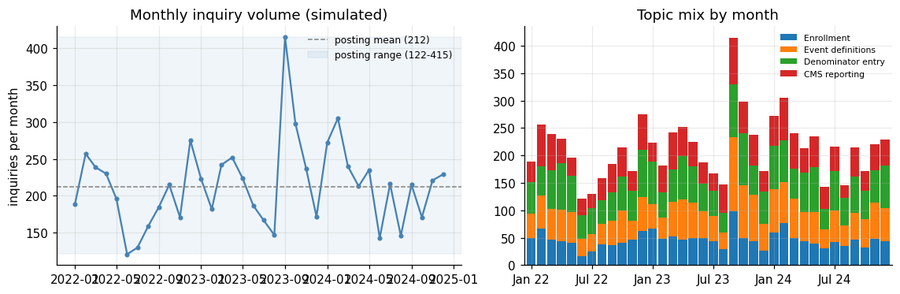

In [3]:
mix = inq.groupby(["month", "topic"]).size().unstack().reindex(columns=TOPICS)
mix.index = [d.strftime("%b %y") for d in mix.index]
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.5), gridspec_kw={"width_ratios": [1.1, 1]})
ax[0].plot(months, volume, "o-", ms=3, color="steelblue"); ax[0].axhline(212, color="gray", ls="--", lw=1, label="posting mean (212)")
ax[0].axhspan(122, 415, color="steelblue", alpha=0.08, label="posting range (122-415)"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title("Monthly inquiry volume (simulated)"); ax[0].set_ylabel("inquiries per month")
mix.plot.bar(stacked=True, ax=ax[1], width=0.9, legend=True); ax[1].set_title("Topic mix by month"); ax[1].set_xticks(range(0, 36, 6)); ax[1].set_xticklabels(list(mix.index[::6]), rotation=0)
ax[1].legend(frameon=False, fontsize=7); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

## 2. Models: TF-IDF + logistic regression versus transformers
- **TF-IDF + logistic regression:** word and two-word features, regularization strength chosen by 5-fold cross-validation on the training months. Fast, transparent, strong on keywords.
- **Small transformer (trained from scratch):** 2 encoder layers, 4 attention heads, 64-dimensional embeddings, mean pooling, ensemble of 3 seeds. It only knows words it saw in training.
- **Pretrained sentence embeddings (`all-MiniLM-L6-v2`) + logistic regression:** the "small transformer embedding model" of the plan. It has seen billions of words, so it can place
  "Where do we begin?" near "How do I enroll?" even when those words never appeared in training. Runs only if the model can be downloaded.

Pretrained embeddings are expected to help most on the **novel phrasing** slice. The comparison below tests that expectation rather than assuming it.

In [4]:
tr, te = inq[inq.period == "train"].reset_index(drop=True), inq[inq.period == "test"].reset_index(drop=True)
ytr = tr.topic.map({t: i for i, t in enumerate(TOPICS)}).to_numpy(); yte = te.topic.map({t: i for i, t in enumerate(TOPICS)}).to_numpy()
probs, backend = {}, []

# --- 1. TF-IDF + logistic regression ---
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, lowercase=True)
Xtr_t = tfidf.fit_transform(tr.text); Xte_t = tfidf.transform(te.text)
gs = GridSearchCV(LogisticRegression(max_iter=3000), {"C": [0.3, 1, 3, 10, 30]}, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="f1_macro").fit(Xtr_t, ytr)
lr_tfidf = gs.best_estimator_; probs["TF-IDF + LR"] = lr_tfidf.predict_proba(Xte_t); backend.append(f"TF-IDF + LR (C={gs.best_params_['C']})")

# --- 2. small transformer trained from scratch ---
def tokenize(s): return re.findall(r"[a-z0-9']+", s.lower())
from collections import Counter
cnt = Counter(w for s in tr.text for w in tokenize(s)); vocab = {w: i + 2 for i, (w, c) in enumerate(cnt.most_common()) if c >= 2}   # 0 pad, 1 unknown
MAXLEN = 48
def encode(texts):
    X = np.zeros((len(texts), MAXLEN), dtype=np.int64)
    for i, s in enumerate(texts):
        ids = [vocab.get(w, 1) for w in tokenize(s)][:MAXLEN]; X[i, :len(ids)] = ids
    return torch.from_numpy(X)

class TinyTransformer(nn.Module):
    def __init__(self, n_vocab, n_cls=4, d=64, heads=4, layers=2, ff=128, p=0.1):
        super().__init__()
        self.emb = nn.Embedding(n_vocab, d, padding_idx=0); self.pos = nn.Embedding(MAXLEN, d)
        self.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, ff, p, batch_first=True), layers, enable_nested_tensor=False)
        self.out = nn.Linear(d, n_cls)
    def forward(self, x):
        pad = x == 0
        h = self.enc(self.emb(x) + self.pos(torch.arange(x.size(1))[None]), src_key_padding_mask=pad)
        keep = (~pad).unsqueeze(-1).float()
        return self.out((h * keep).sum(1) / keep.sum(1).clamp(min=1))

def train_tiny(seed, epochs=12):
    torch.manual_seed(seed); net = TinyTransformer(len(vocab) + 2); opt = torch.optim.AdamW(net.parameters(), lr=2e-3, weight_decay=1e-2)
    X, y = encode(tr.text.tolist()), torch.from_numpy(ytr)
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(y))
        for i in range(0, len(y), 64):
            b = perm[i:i + 64]; loss = nn.functional.cross_entropy(net(X[b]), y[b]); opt.zero_grad(); loss.backward(); opt.step()
    return net.eval()
nets = [train_tiny(SEED + s) for s in range(3)]
with torch.no_grad():
    Xte_n = encode(te.text.tolist()); probs["Tiny transformer (from scratch)"] = np.mean([torch.softmax(n(Xte_n), 1).numpy() for n in nets], axis=0)
backend.append(f"tiny transformer from scratch (vocab {len(vocab)} words, 3 seeds)")

# --- 3. pretrained sentence embeddings + logistic regression (needs a download) ---
if not SKIP_PRETRAINED:
    try:
        _ensure("sentence-transformers", "sentence_transformers")
        from sentence_transformers import SentenceTransformer
        st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
        Etr = st.encode(tr.text.tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
        Ete = st.encode(te.text.tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
        gs2 = GridSearchCV(LogisticRegression(max_iter=3000), {"C": [1, 3, 10, 30, 100]}, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="f1_macro").fit(Etr, ytr)
        probs["MiniLM embeddings + LR"] = gs2.best_estimator_.predict_proba(Ete); backend.append(f"pretrained all-MiniLM-L6-v2 + LR (C={gs2.best_params_['C']})")
    except Exception as exc:
        backend.append(f"pretrained embedding model NOT run ({type(exc).__name__}); rerun with internet access to include it")
else:
    backend.append("pretrained embedding model skipped (NHSN_SKIP_PRETRAINED=1); rerun without it to include it")
print("BACKENDS:"); [print("  -", b) for b in backend]

BACKENDS:
  - TF-IDF + LR (C=30)
  - tiny transformer from scratch (vocab 370 words, 3 seeds)
  - pretrained embedding model skipped (NHSN_SKIP_PRETRAINED=1); rerun without it to include it


[None, None, None]

,model,slice,n,accuracy (95% CI),macro F1
0,TF-IDF + LR,All test months,2606,0.850 (0.835 to 0.864),0.843
1,TF-IDF + LR,Familiar phrasing,1805,0.972 (0.965 to 0.980),0.972
2,TF-IDF + LR,Novel phrasing,801,0.573 (0.538 to 0.605),0.483
3,Tiny transformer (from scratch),All test months,2606,0.789 (0.773 to 0.804),0.787
4,Tiny transformer (from scratch),Familiar phrasing,1805,0.971 (0.963 to 0.978),0.970
5,Tiny transformer (from scratch),Novel phrasing,801,0.378 (0.346 to 0.409),0.339


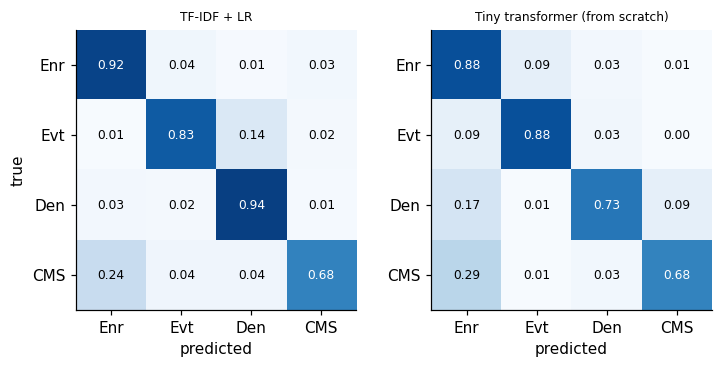

In [5]:
seen_mask = ~te.novel.to_numpy()
pred = {n: p.argmax(1) for n, p in probs.items()}
def boot_acc(y, yhat, mask, B=1000):
    idx = np.flatnonzero(mask); r = np.random.default_rng(7)
    bs = [accuracy_score(y[i], yhat[i]) for i in (r.choice(idx, len(idx)) for _ in range(B))]
    return accuracy_score(y[idx], yhat[idx]), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
rows = []
for n, yh in pred.items():
    for sl, mask in [("All test months", np.ones(len(te), bool)), ("Familiar phrasing", seen_mask), ("Novel phrasing", ~seen_mask)]:
        a, lo, hi = boot_acc(yte, yh, mask)
        rows.append({"model": n, "slice": sl, "n": int(mask.sum()), "accuracy (95% CI)": f"{a:.3f} ({lo:.3f} to {hi:.3f})", "macro F1": round(f1_score(yte[mask], yh[mask], average="macro"), 3)})
res = pd.DataFrame(rows); display(res)

names = list(pred)
fig, ax = plt.subplots(1, len(names), figsize=(3.4 * len(names), 3.3))
for a, n in zip(np.atleast_1d(ax), names):
    cm = confusion_matrix(yte, pred[n], normalize="true")
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1); a.set_xticks(range(4)); a.set_yticks(range(4)); a.set_xticklabels(["Enr", "Evt", "Den", "CMS"]); a.set_yticklabels(["Enr", "Evt", "Den", "CMS"])
    for i in range(4):
        for j in range(4): a.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.5 else "black")
    a.set_title(n, fontsize=8); a.set_xlabel("predicted"); a.grid(False)
np.atleast_1d(ax)[0].set_ylabel("true")
plt.tight_layout(); plt.show()

**Reading the comparison.** Compare the *novel phrasing* slice, not only the overall number. A bag-of-words model is hard to beat when users use the expected keywords; the gap between
slices shows how much each model depends on exact wording. The per-class table and error examples below show where mistakes concentrate.

In [6]:
best_name = max(pred, key=lambda n: accuracy_score(yte, pred[n]))
rep = pd.DataFrame(classification_report(yte, pred[best_name], target_names=TOPICS, output_dict=True)).T.loc[TOPICS + ["macro avg"], ["precision", "recall", "f1-score", "support"]].round(3)
print(f"Per-topic results for the most accurate model overall: {best_name}"); display(rep)
wrong = te.assign(pred=[TOPICS[i] for i in pred[best_name]])[pred[best_name] != yte]
print(f"{len(wrong)} of {len(te)} test messages misrouted ({100 * len(wrong) / len(te):.1f}%). By kind of message, error rate:")
display((te.assign(err=pred[best_name] != yte).groupby("kind").err.agg(["mean", "size"]).rename(columns={"mean": "error rate", "size": "n"}).round(3)))
print("Examples of misrouted messages:")
for _, r_ in wrong.sample(min(6, len(wrong)), random_state=1).iterrows():
    print(f"  true={r_.topic:18s} predicted={r_.pred:18s} | {r_.text[:80]}")

Per-topic results for the most accurate model overall: TF-IDF + LR


,precision,recall,f1-score,support
Enrollment,0.754,0.923,0.830,545.0
Event definitions,0.905,0.833,0.867,694.0
Denominator entry,0.850,0.940,0.893,779.0
CMS reporting,0.913,0.682,0.781,588.0
macro avg,0.856,0.844,0.843,2606.0


392 of 2606 test messages misrouted (15.0%). By kind of message, error rate:


,error rate,n
kind,,
novel,0.382,743
novel+mixed,1.000,58
seen,0.000,1604
seen+mixed,0.015,132
vague,0.696,69


Examples of misrouted messages:
  true=CMS reporting      predicted=Enrollment         | Hello, Our payment could be reduced; what
      do we have to have submitted to the go
  true=CMS reporting      predicted=Enrollment         | will the federal quality program see our
      numbers automatically or must we send s
  true=Event definitions  predicted=CMS reporting      | Good morning, Which of our patient problems
      rise to the level of something we mu
  true=CMS reporting      predicted=Enrollment         | Hi team, Our payment could be reduced; what
      do we have to have submitted to the
  true=Event definitions  predicted=Denominator entry  | Someone started antibiotics by mouth for a
      catheter exit site problem. Is that s
  true=CMS reporting      predicted=Enrollment         | Hi team, Will the federal quality program
      see our numbers automatically or must


### 2.1 Auto-route when confident, send the rest to a person
Misrouting a question wastes a day; asking an analyst to read every message wastes the analyst. A **confidence threshold** splits the stream: confident predictions are routed
automatically, the rest go to a human queue. The threshold is chosen **on the training months only** as the lowest value reaching 95% accuracy among auto-routed messages,
then applied unchanged to the test months. The key question is *how the threshold is validated*:

- **Ordinary cross-validation** only ever tests on phrasings the model has seen, so it looks excellent at every threshold and picks a useless one.
- **Family-held-out cross-validation** removes whole template families from training in each fold, which rehearses what happens when users phrase things in a new way.

Both are reported so the difference is visible.

,threshold chosen by,cross-val accuracy (all),threshold,auto-routed,accuracy of auto-routed,sent to a person
0,Ordinary cross-validation,0.976,0.30,99.9%,85.0%,0.1%
1,Family-held-out cross-validation,0.497,0.95,66.9%,96.8%,33.1%


Using the family-held-out threshold (0.95): at the posting's 212 messages per month, about 142 are
    auto-routed (about 5 of them misrouted) and 70 go to an analyst.


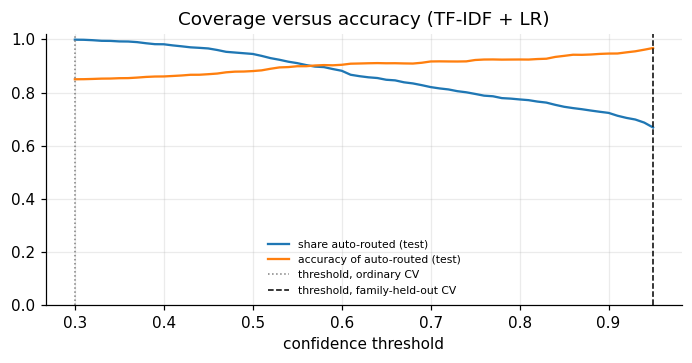

In [7]:
from sklearn.model_selection import GroupKFold
lr_c = LogisticRegression(max_iter=3000, C=gs.best_params_["C"])
cv_iid = cross_val_predict(lr_c, Xtr_t, ytr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")
cv_grp = cross_val_predict(lr_c, Xtr_t, ytr, cv=GroupKFold(5), groups=tr.family.to_numpy(), method="predict_proba")
grid = np.round(np.arange(0.30, 0.96, 0.01), 2)
def pick_tau(cvp, y_true, target=0.95):
    conf, ok = cvp.max(1), cvp.argmax(1) == y_true
    for t_ in grid:
        if (conf >= t_).sum() > 50 and ok[conf >= t_].mean() >= target: return float(t_), float(ok.mean())
    return float(grid[-1]), float(ok.mean())
tau_iid, acc_iid = pick_tau(cv_iid, ytr); tau_grp, acc_grp = pick_tau(cv_grp, ytr)
p_te = probs["TF-IDF + LR"]; conf_te, ok_te = p_te.max(1), p_te.argmax(1) == yte
rows = []
for lab, tau_, acc_cv in [("Ordinary cross-validation", tau_iid, acc_iid), ("Family-held-out cross-validation", tau_grp, acc_grp)]:
    auto = conf_te >= tau_
    rows.append({"threshold chosen by": lab, "cross-val accuracy (all)": round(acc_cv, 3), "threshold": tau_, "auto-routed": f"{100 * auto.mean():.1f}%",
                 "accuracy of auto-routed": f"{100 * ok_te[auto].mean():.1f}%" if auto.any() else "n/a", "sent to a person": f"{100 * (1 - auto.mean()):.1f}%"})
tau_tbl = pd.DataFrame(rows); display(tau_tbl)
tau = tau_grp; auto = conf_te >= tau
perm = 212
print(f"Using the family-held-out threshold ({tau:.2f}): at the posting's 212 messages per month, about {perm * auto.mean():.0f} are auto-routed (about {perm * auto.mean() * (1 - ok_te[auto].mean()):.0f} of them misrouted) and "
      f"{perm * (1 - auto.mean()):.0f} go to an analyst.")
cov_curve = [(conf_te >= t_).mean() for t_ in grid]; acc_curve = [ok_te[conf_te >= t_].mean() if (conf_te >= t_).sum() > 30 else np.nan for t_ in grid]
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(grid, cov_curve, label="share auto-routed (test)"); ax.plot(grid, acc_curve, label="accuracy of auto-routed (test)")
ax.axvline(tau_iid, color="gray", ls=":", lw=1, label="threshold, ordinary CV"); ax.axvline(tau_grp, color="k", ls="--", lw=1, label="threshold, family-held-out CV")
ax.set_xlabel("confidence threshold"); ax.set_ylim(0, 1.02); ax.legend(frameon=False, fontsize=7); ax.set_title("Coverage versus accuracy (TF-IDF + LR)")
plt.tight_layout(); plt.show()

**Reading the thresholds.** Ordinary cross-validation reports about 98% accuracy at every threshold, so it picks the lowest threshold in the grid and routes essentially everything; on the
test months that means roughly 85% accuracy for nearly all messages. Family-held-out cross-validation is honest about novel phrasing (accuracy near 50%) and picks the strictest threshold
in the grid (0.95): roughly two thirds of test messages are routed automatically at about 97% accuracy, and the rest go to a person. The rule works because the model is confidently right on
phrasings it knows and uncertain on ones it does not. Validation that rehearses the deployment shift is what made the rule safe.

## 3. Forecasting monthly inquiry volume for staffing
Staffing needs a **range**, not a single number. Four forecasters are compared with **rolling-origin evaluation** (fit on the past, forecast the next three months, then roll forward),
the honest way to test a forecaster:

- **Seasonal naive:** "same month last year" (the baseline everything must beat).
- **ETS:** exponential smoothing with additive seasonality.
- **SARIMAX:** seasonal autoregression.
- **Negative binomial regression** on a linear trend and two seasonal harmonics (a count model with a natural predictive distribution).

Metrics: mean absolute error (MAE), error relative to the seasonal naive baseline, and the **coverage of 80% prediction intervals** (about 80% of actual values should fall inside).
No model can foresee an unplanned surge, so a protocol-update spike is also a test of how intervals behave.

,model,MAE,MAE vs seasonal naive,80% PI coverage,mean PI width
0,Seasonal naive,60.1,1.00,0.73,151.0
1,ETS (additive seasonal),45.6,0.76,0.60,110.0
2,"SARIMAX (1,0,0)(1,0,0,12)",34.6,0.58,0.83,152.0
3,Negative binomial regression,59.3,0.99,0.57,125.0


Rolling-origin test: 10 origins x 3 horizons = 30 forecasts per model | target coverage 0.80


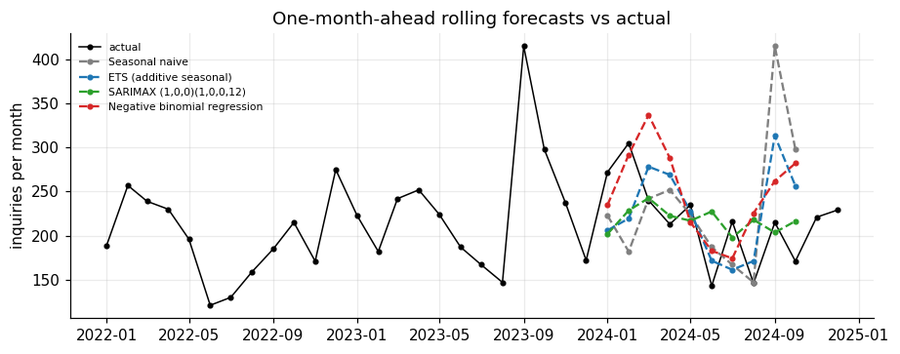

In [8]:
y = pd.Series(volume.astype(float), index=months)
HAR = lambda t: np.column_stack([np.sin(2 * np.pi * t / 12), np.cos(2 * np.pi * t / 12), np.sin(4 * np.pi * t / 12), np.cos(4 * np.pi * t / 12)])
def design(t): return sm.add_constant(np.column_stack([t, HAR(t)]), has_constant="add")
Z80 = stats.norm.ppf(0.9)

def fc_snaive(train, h):
    base = train.values[-12:][:h]; d = train.values[12:] - train.values[:-12]
    return base, base + np.quantile(d, 0.1), base + np.quantile(d, 0.9)
def fc_ets(train, h):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); res = ETSModel(train, error="add", trend=None, seasonal="add", seasonal_periods=12).fit(disp=False)
    sf = res.get_prediction(start=len(train), end=len(train) + h - 1).summary_frame(alpha=0.2)
    return sf["mean"].values, sf["pi_lower"].values, sf["pi_upper"].values
def fc_sarimax(train, h):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); res = SARIMAX(train.values, order=(1, 0, 0), seasonal_order=(1, 0, 0, 12), trend="c").fit(disp=False)
    f = res.get_forecast(h); ci = f.conf_int(alpha=0.2); return f.predicted_mean, ci[:, 0], ci[:, 1]
def fc_nb(train, h):
    t = np.arange(len(train))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); res = sm.NegativeBinomial(train.values, design(t)).fit(disp=0, maxiter=500, method="bfgs")
    beta, alpha = res.params[:-1], float(res.params[-1]); tf = np.arange(len(train), len(train) + h)
    mu = np.exp(design(tf) @ beta); n = 1 / max(alpha, 1e-6); p = n / (n + mu)
    return mu, stats.nbinom.ppf(0.1, n, p), stats.nbinom.ppf(0.9, n, p)
FORECASTERS = {"Seasonal naive": fc_snaive, "ETS (additive seasonal)": fc_ets, "SARIMAX (1,0,0)(1,0,0,12)": fc_sarimax, "Negative binomial regression": fc_nb}

H, ORIGINS = 3, list(range(24, 34))
roll = {n: {"pred": [], "lo": [], "hi": [], "act": [], "h": [], "origin": []} for n in FORECASTERS}
for o in ORIGINS:
    train, act = y.iloc[:o], y.values[o:o + H]
    for n, f in FORECASTERS.items():
        try: p, lo, hi = f(train, H)
        except Exception: p, lo, hi = fc_snaive(train, H)
        r_ = roll[n]; r_["pred"] += list(p); r_["lo"] += list(lo); r_["hi"] += list(hi); r_["act"] += list(act); r_["h"] += [1, 2, 3]; r_["origin"] += [o] * H
rows = []; base_mae = np.mean(np.abs(np.array(roll["Seasonal naive"]["pred"]) - np.array(roll["Seasonal naive"]["act"])))
for n, r_ in roll.items():
    pr, ac, lo, hi = map(np.array, (r_["pred"], r_["act"], r_["lo"], r_["hi"]))
    rows.append({"model": n, "MAE": round(np.mean(np.abs(pr - ac)), 1), "MAE vs seasonal naive": round(np.mean(np.abs(pr - ac)) / base_mae, 2),
                 "80% PI coverage": round(float(np.mean((ac >= lo) & (ac <= hi))), 2), "mean PI width": round(float(np.mean(hi - lo)), 0)})
fc_tbl = pd.DataFrame(rows); display(fc_tbl)
print(f"Rolling-origin test: {len(ORIGINS)} origins x {H} horizons = {len(ORIGINS) * H} forecasts per model | target coverage 0.80")

fig, ax = plt.subplots(figsize=(8.5, 3.4)); ax.plot(months, y.values, "k.-", lw=1, label="actual")
for n, c in zip(FORECASTERS, ["gray", "tab:blue", "tab:green", "tab:red"]):
    r_ = roll[n]; first = [i for i, hh in enumerate(r_["h"]) if hh == 1]
    ax.plot(months[[o for o in np.array(r_["origin"])[first]]], np.array(r_["pred"])[first], "o--", ms=3, color=c, label=n)
ax.set_title("One-month-ahead rolling forecasts vs actual"); ax.set_ylabel("inquiries per month"); ax.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

### 3.1 From forecast to staffing
Assumption (change it to match the real team): **one analyst-equivalent (FTE) can handle about 250 inquiries a month**, and a month above **350** needs surge coverage.
The forecast distribution turns into probabilities of exceeding those thresholds. The model with the lowest rolling-origin MAE produces the forecast (with its coverage reported so its
intervals can be trusted or not).

Forecast model: SARIMAX (1,0,0)(1,0,0,12) (lowest rolling MAE; its 80% PI coverage was 0.83;
    capacity assumption 250/FTE/month, surge above 350)


,month,forecast,80% PI low,80% PI high,P(>250),P(>350),suggested coverage
0,Jan 2025,219.0,148.0,289.0,0.28,0.01,1 FTE
1,Feb 2025,217.0,145.0,288.0,0.28,0.01,1 FTE
2,Mar 2025,215.0,143.0,287.0,0.27,0.01,1 FTE
3,Apr 2025,215.0,143.0,286.0,0.26,0.01,1 FTE
4,May 2025,215.0,143.0,287.0,0.27,0.01,1 FTE
5,Jun 2025,213.0,141.0,285.0,0.26,0.01,1 FTE


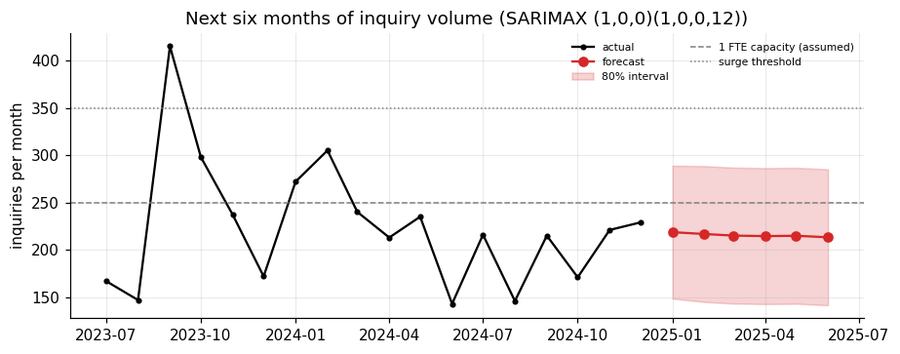

In [9]:
chosen = fc_tbl.sort_values("MAE").iloc[0]["model"]; HF = 6
mean_f, lo_f, hi_f = FORECASTERS[chosen](y, HF)
fm = pd.date_range("2025-01-01", periods=HF, freq="MS"); sd = np.maximum((hi_f - lo_f) / (2 * Z80), 1e-6)
CAP, SURGE = 250, 350
plan = pd.DataFrame({"month": fm.strftime("%b %Y"), "forecast": np.round(mean_f), "80% PI low": np.round(lo_f), "80% PI high": np.round(hi_f),
                     "P(>250)": np.round(1 - stats.norm.cdf(CAP, mean_f, sd), 2), "P(>350)": np.round(1 - stats.norm.cdf(SURGE, mean_f, sd), 2)})
plan["suggested coverage"] = np.where(plan["P(>350)"] > 0.10, "surge plan (2 FTE)", np.where(plan["P(>250)"] > 0.30, "1 FTE + backup", "1 FTE"))
print(f"Forecast model: {chosen} (lowest rolling MAE; its 80% PI coverage was {float(fc_tbl.set_index('model').loc[chosen, '80% PI coverage']):.2f}; capacity assumption {CAP}/FTE/month, surge above {SURGE})")
display(plan)
fig, ax = plt.subplots(figsize=(8.5, 3.4)); ax.plot(months[-18:], y.values[-18:], "k.-", label="actual")
ax.plot(fm, mean_f, "o-", color="tab:red", label="forecast"); ax.fill_between(fm, lo_f, hi_f, color="tab:red", alpha=0.2, label="80% interval")
ax.axhline(CAP, color="gray", ls="--", lw=1, label="1 FTE capacity (assumed)"); ax.axhline(SURGE, color="gray", ls=":", lw=1, label="surge threshold")
ax.set_title(f"Next six months of inquiry volume ({chosen})"); ax.set_ylabel("inquiries per month"); ax.legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

**Reading the forecast.** Three points. (1) The seasonal naive baseline copies last year's value, noise included, so it is hard to beat only if seasonality is strong; here SARIMAX
has the lowest error and the best interval coverage (close to the 80% target) while ETS and the negative binomial regression under-cover. (2) The forecast is nearly flat: with only three years of data,
the seasonal swing is small relative to month-to-month noise, so the honest message is "about 215 a month, with a wide range", and the probability of exceeding one FTE's capacity matters more than the point
forecast. (3) The 2024 test window contains **no surge**, so how these models and intervals behave when an unplanned spike (such as a protocol update) arrives is **not tested here**. Surge planning needs
a calendar of known events and a standing escalation plan, not a better model.

# Part B. Automated facility reports

## 4. Rebuild the notebook 01 world
Compact copy of notebook 01 (configuration, generator, error injection, validation rules), collapsed in Colab. **Do not change the seed or the order.**

In [10]:
#@title Recap from notebook 01: config { display-mode: "form" }
N_FACILITIES = 160
MONTHS = pd.period_range("2023-01", "2024-12", freq="M")      # 24 reporting months
ACCESS = ["AVF", "AVG", "CVC_tunneled", "CVC_nontunneled", "Other"]
EVENT_TYPES = ["positive_blood_culture", "iv_antimicrobial_start", "pus_redness_swelling"]

# Illustrative baseline rates per 100 patient-months, by access type (columns follow EVENT_TYPES order).
BASE_RATE = {
    "AVF":             [0.15, 0.45, 0.10],
    "AVG":             [0.35, 0.90, 0.25],
    "CVC_tunneled":    [1.10, 2.00, 0.40],
    "CVC_nontunneled": [2.50, 3.50, 0.80],
    "Other":           [0.30, 0.80, 0.20],
}

LATE_DAYS = 30           # submission later than this many days after month end counts as late
DUP_WINDOW_DAYS = 21     # same patient + same event type within this window = duplicate (illustrative rule)
MIN_PLAUSIBLE_YEAR = 2015

# Probability each record is hit by an injected error (facility-month level, then event level).
ERR_RATES = dict(
    missing=0.020, patient_typo=0.015, sum_mismatch=0.020, zero_access=0.030, late=0.030, inflation=0.025,
    duplicate=0.020, date_outside=0.015, date_implausible=0.007, access_swapped=0.015,
)
print(f"{N_FACILITIES} facilities x {len(MONTHS)} months = {N_FACILITIES*len(MONTHS):,} facility-months")

160 facilities x 24 months = 3,840 facility-months


In [11]:
#@title Recap from notebook 01: generator { display-mode: "form" }
def make_facilities(n, rng):
    states = ["FL", "GA", "TX", "CA", "NY", "OH", "PA", "IL", "NC", "MI"]
    state_network = {s: f"NW-{(i % 6) + 1:02d}" for i, s in enumerate(states)}   # synthetic network codes
    fac = pd.DataFrame({"facility_id": [f"FAC{i+1:04d}" for i in range(n)]})
    fac["state"] = rng.choice(states, n)
    fac["network"] = fac["state"].map(state_network)
    fac["ownership"] = rng.choice(["Large_chain", "Nonprofit", "Independent"], n, p=[0.60, 0.25, 0.15])
    fac["urban_rural"] = rng.choice(["Urban", "Rural"], n, p=[0.78, 0.22])
    size = rng.lognormal(np.log(65), 0.45, n) * np.where(fac["urban_rural"] == "Rural", 0.7, 1.0)
    fac["mean_census"] = np.clip(size, 15, 250).round().astype(int)
    base_mix = np.array([0.62, 0.13, 0.17, 0.02, 0.06])
    mix = np.vstack([rng.dirichlet(base_mix * 60) for _ in range(n)])
    for j, a in enumerate(ACCESS):
        fac[f"mix_{a}"] = mix[:, j]
    fac["log_effect"] = rng.normal(0, 0.35, n)             # latent facility risk (ground truth, never used as a feature)
    fac["in_collaborative"] = rng.random(n) < 0.40
    return fac


def make_clean_denominator(fac, months, rng):
    rows, mix_cols = [], [f"mix_{a}" for a in ACCESS]
    for f in fac.itertuples(index=False):
        mix = np.array([getattr(f, c) for c in mix_cols]); mix = mix / mix.sum()
        drift = rng.normal(0.002, 0.003)                    # slow census growth/decline
        for t, m in enumerate(months):
            start = m.to_timestamp()
            end = (m + 1).to_timestamp() - pd.Timedelta(days=1)
            total = max(8, int(round(f.mean_census * (1 + drift * t) * (1 + rng.normal(0, 0.025)))))
            counts = rng.multinomial(total, mix)
            delay = int(np.clip(rng.gamma(2.0, 5.0), 3, 28))   # typical on-time submission
            rows.append({"facility_id": f.facility_id, "month": start,
                         "report_date": end + pd.Timedelta(days=delay), "patients_total": total,
                         **{f"n_{a}": int(c) for a, c in zip(ACCESS, counts)}})
    return pd.DataFrame(rows)


def make_clean_events(fac, den, rng):
    info = fac.set_index("facility_id")[["log_effect", "in_collaborative", "mean_census"]].to_dict("index")
    collab_start, rows = pd.Timestamp("2024-01-01"), []
    for r in den.itertuples(index=False):
        f = info[r.facility_id]
        ndays = r.month.days_in_month
        post = bool(f["in_collaborative"]) and r.month >= collab_start
        shock = rng.gamma(20, 1 / 20)                         # monthly extra-Poisson variation
        pool = int(f["mean_census"] * 1.6)
        for a in ACCESS:
            n_a = getattr(r, f"n_{a}")
            if n_a == 0:
                continue
            mult = 0.7 if (post and a.startswith("CVC")) else 1.0
            for k, et in enumerate(EVENT_TYPES):
                lam = n_a * BASE_RATE[a][k] / 100 * np.exp(f["log_effect"]) * shock * mult
                for _ in range(rng.poisson(lam)):
                    rows.append({"facility_id": r.facility_id, "month": r.month,
                                 "patient_id": f"{r.facility_id}-P{rng.integers(1, pool + 1):04d}",
                                 "event_type": et, "access_type": a,
                                 "event_date": r.month + pd.Timedelta(days=int(rng.integers(0, ndays)))})
    return pd.DataFrame(rows)


def enforce_dup_window(ev, window=DUP_WINDOW_DAYS):
    """Clean data should already obey the duplicate-event rule: drop a repeat for the same patient/type inside the window."""
    ev = ev.sort_values(["facility_id", "patient_id", "event_type", "event_date"]).reset_index(drop=True)
    keep, last_key, last_date = np.ones(len(ev), bool), None, None
    for i, (fid, pid, et, d) in enumerate(zip(ev.facility_id, ev.patient_id, ev.event_type, ev.event_date)):
        key = (fid, pid, et)
        if key == last_key and (d - last_date).days <= window:
            keep[i] = False
            continue
        last_key, last_date = key, d
    return ev[keep].reset_index(drop=True)


fac = make_facilities(N_FACILITIES, rng)
den_clean = make_clean_denominator(fac, MONTHS, rng)
ev_clean = enforce_dup_window(make_clean_events(fac, den_clean, rng))
ev_clean = ev_clean.sort_values(["facility_id", "month", "event_date"]).reset_index(drop=True)
ev_clean.insert(0, "event_id", [f"EV{i+1:06d}" for i in range(len(ev_clean))])

In [12]:
#@title Recap from notebook 01: error injection { display-mode: "form" }
def _append_label(ev, mask, label):
    cur = ev.loc[mask, "err_event"]
    ev.loc[mask, "err_event"] = np.where(cur == "", label, cur + "|" + label)


def inject_errors(den_c, ev_c, rng, rates=ERR_RATES):
    den, ev = den_c.copy(), ev_c.copy()
    n = len(den)
    cnt_cols = [f"n_{a}" for a in ACCESS]
    month_end = den["month"] + pd.offsets.MonthEnd(0)

    T = pd.DataFrame({"facility_id": den.facility_id, "month": den.month})
    for k in ["missing", "patient_typo", "sum_mismatch", "zero_access", "late", "inflation"]:
        T[k] = rng.random(n) < rates[k]

    # --- facility-month errors on the denominator ---
    m = T.patient_typo.to_numpy()
    den.loc[m, ["patients_total"] + cnt_cols] = den.loc[m, ["patients_total"] + cnt_cols] * 10

    m = T.sum_mismatch.to_numpy()
    factor = 1 + rng.choice([-1, 1], m.sum()) * rng.uniform(0.08, 0.20, m.sum())
    den.loc[m, "patients_total"] = (den.loc[m, "patients_total"] * factor).round().astype(int)

    ev_by_key = ev_c.groupby(["facility_id", "month"])["access_type"].apply(list).to_dict()
    za_map = {}
    for i in np.flatnonzero(T.zero_access.to_numpy()):
        key = (den.at[i, "facility_id"], den.at[i, "month"])
        cands = sorted(a for a in set(ev_by_key.get(key, [])) if a != "AVF" and den_c.at[i, f"n_{a}"] > 0)   # sorted: set order varies between Python processes
        if not cands:
            T.at[i, "zero_access"] = False
            continue
        a = cands[int(rng.integers(len(cands)))]
        den.at[i, "n_AVF"] += den.at[i, f"n_{a}"]       # patients moved to AVF; total stays consistent
        den.at[i, f"n_{a}"] = 0
        za_map[key] = a

    m = T.late.to_numpy()
    den.loc[m, "report_date"] = month_end[m] + pd.to_timedelta(rng.integers(35, 91, m.sum()), unit="D")

    # --- event-level errors ---
    ev = ev.merge(den[["facility_id", "month", "report_date"]], on=["facility_id", "month"], how="left")
    ev["err_event"] = ""
    N = len(ev)
    k_out, k_imp, k_swap = (int(N * rates[x]) for x in ("date_outside", "date_implausible", "access_swapped"))
    perm = rng.permutation(N)
    i_out, i_imp = perm[:k_out], perm[k_out:k_out + k_imp]
    i_swap = perm[k_out + k_imp:k_out + k_imp + k_swap]
    i_dup = rng.choice(perm[k_out + k_imp + k_swap:], int(N * rates["duplicate"]), replace=False)

    shift = (rng.choice([-1, 1], k_out) * rng.integers(35, 70, k_out))
    ev.loc[i_out, "event_date"] = ev.loc[i_out, "event_date"].to_numpy() + pd.to_timedelta(shift, unit="D").to_numpy()
    half = len(i_imp) // 2
    ev.loc[i_imp[:half], "event_date"] = pd.Timestamp("1900-01-01")
    ev.loc[i_imp[half:], "event_date"] = ev.loc[i_imp[half:], "report_date"] + pd.Timedelta(days=180)
    ev.loc[i_swap, "access_type"] = [rng.choice([x for x in ACCESS if x != a]) for a in ev.loc[i_swap, "access_type"]]
    for idx, lab in [(i_out, "date_outside_month"), (i_imp, "date_implausible"), (i_swap, "access_swapped")]:
        ev.loc[idx, "err_event"] = lab

    dups = ev.loc[i_dup].copy()
    dups["event_id"] = "EVD" + dups["event_id"].str[2:]
    shifted = dups["event_date"] + pd.to_timedelta(rng.integers(1, 15, len(dups)), unit="D")
    dups["event_date"] = pd.concat([shifted, dups["month"] + pd.offsets.MonthEnd(0)], axis=1).min(axis=1)
    dups["err_event"] = "duplicate"

    # over-reporting: valid-looking extra events for new patient IDs, so no event-level rule can catch them
    extra, c = [], 0
    for i in np.flatnonzero(T.inflation.to_numpy()):
        r = den_c.iloc[i]
        w = np.array([r[f"n_{a}"] * sum(BASE_RATE[a]) for a in ACCESS], float)
        for _ in range(int(rng.integers(3, 8))):
            c += 1
            a = ACCESS[int(rng.choice(len(ACCESS), p=w / w.sum()))]
            extra.append({"event_id": f"EVX{c:06d}", "facility_id": r.facility_id, "month": r.month,
                          "patient_id": f"{r.facility_id}-X{c:05d}", "event_type": str(rng.choice(EVENT_TYPES)),
                          "access_type": a,
                          "event_date": r.month + pd.Timedelta(days=int(rng.integers(0, r.month.days_in_month))),
                          "report_date": den.at[i, "report_date"], "err_event": "inflated_valid"})
    ev = pd.concat([ev, dups, pd.DataFrame(extra)], ignore_index=True)

    # label events caused by facility-month problems, then apply missing denominators
    zero_flag = np.array([za_map.get((f, mo)) == a for f, mo, a in zip(ev.facility_id, ev.month, ev.access_type)])
    _append_label(ev, zero_flag, "den_zero_access")
    miss_keys = set(zip(T.loc[T.missing, "facility_id"], T.loc[T.missing, "month"]))
    _append_label(ev, np.array([k in miss_keys for k in zip(ev.facility_id, ev.month)]), "no_denominator")

    den_sub = den.loc[~T.missing.to_numpy()].reset_index(drop=True)
    truth_ev = ev[["event_id", "err_event"]].copy()
    ev_sub = ev.drop(columns="err_event").sort_values(["facility_id", "month", "event_id"]).reset_index(drop=True)
    T["has_fm_error"] = T[["patient_typo", "sum_mismatch", "zero_access", "late", "inflation"]].any(axis=1)
    return den_sub, ev_sub, truth_ev, T


den, ev, truth_ev, truth_fm = inject_errors(den_clean, ev_clean, rng)

In [13]:
#@title Recap from notebook 01: rule registry { display-mode: "form" }
RULES = pd.DataFrame([
    ("R1_date_outside_month", "event", 2, "Event date falls outside the reporting month it was entered under",
     "Hard stop at data entry when event date is outside the selected reporting month",
     "State that the event date, not the entry date, determines the reporting month."),
    ("R2_date_implausible", "event", 3, f"Event date before {MIN_PLAUSIBLE_YEAR} or after the submission date",
     "Block future dates and dates before facility enrollment",
     "Remind users that placeholder dates (for example 01/01/1900) must never be used."),
    ("R3_no_denominator", "event", 3, "Event reported for a facility-month with no submitted denominator",
     "Prevent saving events for a month until its denominator is submitted (or show a blocking alert)",
     "Add a step: complete the monthly denominator before entering events."),
    ("R4_zero_access_denominator", "event", 2, "Event access type has zero patients in that month's denominator",
     "Cross-field warning when event access type has a zero denominator count",
     "Clarify that denominator access-type counts must reflect each patient's access on the first two working days."),
    ("R5_duplicate_21d", "event", 2, f"Same patient and event type repeated within {DUP_WINDOW_DAYS} days",
     "Possible-duplicate alert that shows the earlier event at entry",
     "Add a worked example of the repeat-event window to the form instructions (confirm against current protocol)."),
    ("R6_missing_month", "facility-month", 2, "Enrolled facility has no denominator for a reporting month",
     "Automated missing-data report and reminder to facilities",
     "Add a monthly 'no events to report' attestation pathway."),
    ("R7_events_exceed_patients", "facility-month", 3, "Events for an access type exceed patients in that access category",
     "Numerator/denominator consistency check on submit",
     "Explain how event access type maps to denominator categories."),
    ("R8a_access_sum_mismatch", "facility-month", 2, "Total patients does not equal the sum of access-type counts",
     "Auto-calculate the total from access-type fields (read-only total)",
     "Clarify that the total is the sum of the access-type rows."),
    ("R8b_patient_count_outlier", "facility-month", 2, "Patient count is an outlier vs the facility's own history (robust |z| > 5)",
     "Soft warning when census differs sharply from prior months, with confirm button",
     "Add guidance for confirming unusually large or small census values."),
    ("R9_late_submission", "facility-month", 1, f"Submission more than {LATE_DAYS} days after month end",
     "Timeliness dashboard and automatic reminders at day 20 and day 28",
     "State the submission deadline prominently on the form."),
], columns=["rule_id", "level", "severity", "description", "proposed_modification", "form_instruction_edit"])

In [14]:
#@title Recap from notebook 01: validation functions { display-mode: "form" }
ACC_N = [f"n_{a}" for a in ACCESS]
EVENT_RULES = ["R1_date_outside_month", "R2_date_implausible", "R3_no_denominator", "R4_zero_access_denominator", "R5_duplicate_21d"]


def validate_events(ev, den):
    """Return the event line list with one boolean column per event-level rule."""
    e = ev.merge(den[["facility_id", "month"] + ACC_N], on=["facility_id", "month"], how="left", indicator=True)
    e["R3_no_denominator"] = e["_merge"].eq("left_only")
    a_idx = e["access_type"].map({a: i for i, a in enumerate(ACCESS)}).to_numpy()
    n_for_access = e[ACC_N].to_numpy(float)[np.arange(len(e)), a_idx]
    e["R4_zero_access_denominator"] = (~e["R3_no_denominator"]) & (np.nan_to_num(n_for_access, nan=1) == 0)
    e["R1_date_outside_month"] = e["event_date"].dt.to_period("M") != e["month"].dt.to_period("M")
    e["R2_date_implausible"] = (e["event_date"].dt.year < MIN_PLAUSIBLE_YEAR) | (e["event_date"] > e["report_date"])
    s = e.sort_values(["facility_id", "patient_id", "event_type", "event_date", "event_id"])
    same = (s[["facility_id", "patient_id", "event_type"]].shift().eq(s[["facility_id", "patient_id", "event_type"]]).all(axis=1))
    close = (s["event_date"] - s["event_date"].shift()).dt.days.between(0, DUP_WINDOW_DAYS)
    dup_ids = set(s.loc[same & close, "event_id"])
    e["R5_duplicate_21d"] = e["event_id"].isin(dup_ids)
    e["any_event_rule"] = e[EVENT_RULES].any(axis=1)
    return e.drop(columns=ACC_N + ["_merge"])


def validate_facility_months(den, ev_flags, months, fac_ids):
    grid = pd.MultiIndex.from_product([fac_ids, [m.to_timestamp() for m in months]],
                                      names=["facility_id", "month"]).to_frame(index=False)
    d = grid.merge(den, on=["facility_id", "month"], how="left")
    d["R6_missing_month"] = d["patients_total"].isna()
    present = ~d["R6_missing_month"]

    cnt = ev_flags.pivot_table(index=["facility_id", "month"], columns="access_type", values="event_id",
                               aggfunc="count", fill_value=0).reindex(columns=ACCESS, fill_value=0)
    cnt.columns = [f"ev_{a}" for a in ACCESS]
    d = d.merge(cnt.reset_index(), on=["facility_id", "month"], how="left")
    ev_cols = [f"ev_{a}" for a in ACCESS]
    d[ev_cols] = d[ev_cols].fillna(0).astype(int)
    d["events_total"] = d[ev_cols].sum(axis=1)

    d["R4_any"] = d.merge(ev_flags.groupby(["facility_id", "month"])["R4_zero_access_denominator"].any().rename("x").reset_index(),
                          on=["facility_id", "month"], how="left")["x"].fillna(False).astype(bool).to_numpy()
    d["R7_events_exceed_patients"] = present & (d[ev_cols].to_numpy() > d[ACC_N].fillna(0).to_numpy()).any(axis=1)
    d["R8a_access_sum_mismatch"] = present & (d["patients_total"] != d[ACC_N].sum(axis=1))
    lp = np.log(d["patients_total"].clip(lower=1))
    dev = lp - lp.groupby(d["facility_id"]).transform("median")
    mad = dev.abs().groupby(d["facility_id"]).transform("median")
    d["log_pat_dev"] = dev
    d["robust_z_patients"] = dev / np.maximum(1.4826 * mad, 0.03)       # floor avoids dividing by ~0
    d["R8b_patient_count_outlier"] = present & (d["robust_z_patients"].abs() > 5)
    d["delay_days"] = (d["report_date"] - (d["month"] + pd.offsets.MonthEnd(0))).dt.days
    d["R9_late_submission"] = present & (d["delay_days"] > LATE_DAYS)
    d["rule_fm_count"] = d[["R4_any", "R7_events_exceed_patients", "R8a_access_sum_mismatch",
                            "R8b_patient_count_outlier", "R9_late_submission"]].sum(axis=1)
    d["rule_fm_flag"] = d["rule_fm_count"] > 0
    return d


E = validate_events(ev, den)
D = validate_facility_months(den, E, MONTHS, fac.facility_id.tolist())

In [15]:
print(f"Recap done: {len(fac)} facilities, {len(den):,} denominator rows, {len(ev):,} submitted events; "
      f"{int(E.any_event_rule.sum())} events and {int(D.rule_fm_flag.sum())} facility-months flagged by the rules")

Recap done: 160 facilities, 3,758 denominator rows, 4,365 submitted events; 314 events and 314
    facility-months flagged by the rules


## 5. What goes on the page
One page per facility for the reporting year (**2024**, the last four quarters), written for the people who use it: infection preventionists, nurse managers, and administrators.

| Block | Content | Method (from earlier notebooks) |
|---|---|---|
| Headline | One sentence: higher than, about as, or lower than expected | Observed vs expected events with an exact 95% Poisson interval (notebook 02) |
| Key numbers | Events, expected events, ratio, rate per 100 patient-months, share of patients with a catheter | Validated records only (notebook 01) |
| Trend and benchmark | Quarterly rate against the middle half of all facilities | Benchmarks come from the same reporting period |
| Data quality | Score out of 100 with the specific problems found | Simplified version of the notebook 01 scorecard (no machine-learning component) |
| What to do next | Rule-based suggestions tied to the findings and to CDC's Core Interventions | Written in advance, reviewed by people |

**Readability is checked automatically** with the Flesch-Kincaid grade level; the goal is grade 8 or below for the narrative.

In [16]:
bad_fm = D.R6_missing_month | D.rule_fm_flag
bad_keys = set(zip(D.loc[bad_fm, "facility_id"], D.loc[bad_fm, "month"]))
ev_ok = E[~E.any_event_rule & ~pd.Series(list(zip(E.facility_id, E.month))).isin(bad_keys).to_numpy()].copy()
d_ok = D[~bad_fm].copy()
long = d_ok[["facility_id", "month"] + ACC_N].melt(id_vars=["facility_id", "month"], var_name="access", value_name="pm")
long["access"] = long["access"].str.replace("n_", "", regex=False)
cnt_ = ev_ok.groupby(["facility_id", "month", "access_type"]).size().rename("events").reset_index().rename(columns={"access_type": "access"})
long = long.merge(cnt_, on=["facility_id", "month", "access"], how="left").fillna({"events": 0})
long["q"] = ((long["month"].dt.year - 2023) * 12 + long["month"].dt.month - 1) // 3 + 1
fac_ids = sorted(fac.facility_id); F, NQ, NA = len(fac_ids), 8, len(ACCESS)
qa = (long.groupby(["facility_id", "q", "access"]).agg(pm=("pm", "sum"), events=("events", "sum"))
      .reindex(pd.MultiIndex.from_product([fac_ids, range(1, NQ + 1), ACCESS], names=["facility_id", "q", "access"]), fill_value=0))
PM = qa["pm"].to_numpy(float).reshape(F, NQ, NA); EV = qa["events"].to_numpy(float).reshape(F, NQ, NA)
CVC_IDX = [ACCESS.index("CVC_tunneled"), ACCESS.index("CVC_nontunneled")]

def poisson_exact_ci(k, alpha=0.05):
    k = np.asarray(k, float)
    return (np.where(k > 0, stats.chi2.ppf(alpha / 2, 2 * np.maximum(k, 1)) / 2, 0.0), stats.chi2.ppf(1 - alpha / 2, 2 * (k + 1)) / 2)

PER = slice(4, 8)                                         # quarters 5-8 = calendar year 2024
pm_a, ev_a = PM[:, PER, :].sum(1), EV[:, PER, :].sum(1)
pooled = ev_a.sum(0) / pm_a.sum(0)                        # access-specific rates across all facilities, same year
E_f, O_f = pm_a @ pooled, ev_a.sum(1)
lo_o, hi_o = poisson_exact_ci(O_f)
rate_all = 100 * O_f / pm_a.sum(1)
cvc_share = pm_a[:, CVC_IDX].sum(1) / pm_a.sum(1)
pm_q = PM.sum(2); med_pm = np.median(pm_q, axis=1, keepdims=True)
q_rate = np.where(pm_q >= 0.5 * med_pm, 100 * EV.sum(2) / np.maximum(pm_q, 1), np.nan)    # facility x quarter; NaN (a gap) where too little data was submitted, never a false zero
bench_q = np.nanpercentile(q_rate, [25, 50, 75], axis=0)           # middle half of facilities, each quarter

# --- data-quality components for 2024 (simplified notebook 01 scorecard) ---
D24 = D[D.month >= "2024-01-01"]; E24 = E[E.month >= "2024-01-01"]
pres = D24[~D24.R6_missing_month]
den_bad = pres[["R4_any", "R7_events_exceed_patients", "R8a_access_sum_mismatch", "R8b_patient_count_outlier"]].any(axis=1)
dq = pd.DataFrame({
    "months_missing": D24.groupby("facility_id").R6_missing_month.sum(),
    "months_late": pres.groupby("facility_id").R9_late_submission.sum(),
    "months_inconsistent": den_bad.groupby(pres.facility_id).sum(),
    "events_with_problems": E24.groupby("facility_id").any_event_rule.sum(),
    "events_submitted": E24.groupby("facility_id").size()}).reindex(fac_ids).fillna(0)
dq["completeness"] = 1 - dq.months_missing / 12
dq["timeliness"] = 1 - dq.months_late / np.maximum(12 - dq.months_missing, 1)
dq["event_validity"] = 1 - dq.events_with_problems / np.maximum(dq.events_submitted, 1)
dq["consistency"] = 1 - dq.months_inconsistent / np.maximum(12 - dq.months_missing, 1)
dq["score"] = 100 * (0.30 * dq.completeness + 0.20 * dq.timeliness + 0.30 * dq.event_validity + 0.20 * dq.consistency)
dq["tier"] = pd.cut(dq.score, [-np.inf, 85, 95, np.inf], labels=["Needs attention", "Good, with items to fix", "Excellent"])
print("Data-quality score by tier:", dq.tier.value_counts().to_dict(), "| median score", round(dq.score.median(), 1))

Data-quality score by tier: {'Excellent': 95, 'Good, with items to fix': 59, 'Needs attention': 6} |
    median score 96.7


In [17]:
def syllables(w):
    w = re.sub(r"[^a-z]", "", w.lower()); n = len(re.findall(r"[aeiouy]+", w))
    if w.endswith("e") and not w.endswith(("le", "ee")) and n > 1: n -= 1
    return max(n, 1) if w else 0
def fk_grade(text):
    sents = max(1, len(re.findall(r"[.!?](\s|$)", text))); words = re.findall(r"[A-Za-z']+", text)
    if not words: return float("nan")
    return 0.39 * len(words) / sents + 11.8 * sum(syllables(w) for w in words) / len(words) - 15.59

def facility_fields(i):
    f = fac_ids[i]; o, e = int(O_f[i]), float(E_f[i]); sir = o / e if e > 0 else float("nan")
    lo, hi = lo_o[i] / e, hi_o[i] / e; share_med = float(np.median(cvc_share))
    cat = "higher" if lo > 1 else ("lower" if hi < 1 else "about")
    pct = float((rate_all < rate_all[i]).mean() * 100)
    d = dq.loc[f]; probs_ = []
    if d.months_missing: probs_.append(f"{int(d.months_missing)} month(s) with no data submitted")
    if d.months_late: probs_.append(f"{int(d.months_late)} month(s) submitted more than 30 days after month end")
    if d.months_inconsistent: probs_.append(f"{int(d.months_inconsistent)} month(s) where patient counts did not add up or looked unusual")
    if d.events_with_problems: probs_.append(f"{int(d.events_with_problems)} event(s) with a date or vascular access problem")
    return dict(fid=f, state=fac.set_index("facility_id").loc[f, "state"], network=fac.set_index("facility_id").loc[f, "network"], o=o, e=e, sir=sir, lo=lo, hi=hi, cat=cat,
                rate=float(rate_all[i]), bench_med=float(np.median(rate_all)), bench_lo=float(np.percentile(rate_all, 25)), bench_hi=float(np.percentile(rate_all, 75)), pct=pct,
                cvc=float(cvc_share[i]), cvc_med=share_med, dq=float(d.score), tier=str(d.tier), dq_problems=probs_, small=e < 3)

HEAD = {"higher": "Your facility reported MORE dialysis events than we would expect.",
        "about": "Your facility reported ABOUT AS MANY dialysis events as we would expect.",
        "lower": "Your facility reported FEWER dialysis events than we would expect."}
def narrative(r):
    t = [HEAD[r["cat"]],
         f"In 2024 your facility reported {r['o']} dialysis events. Based on your patients and the kind of vascular access they have, we would expect about {r['e']:.1f}. "
         f"That is a ratio of {r['sir']:.2f}, with a likely range of {r['lo']:.2f} to {r['hi']:.2f}."]
    if r["cat"] == "about": t.append("The range includes 1.0, so the difference from the expected number could be due to chance.")
    if r["small"]: t.append("Your facility has few expected events, so the ratio can change a lot from one or two events. Look at the trend, not one number.")
    return " ".join(t)
def next_steps(r):
    s = []
    if r["cat"] == "higher": s.append("Review your catheter care, hand hygiene, and catheter hub disinfection checks with your team (CDC Core Interventions).")
    if r["cvc"] > 1.25 * r["cvc_med"]: s.append(f"More of your patients dialyze with a catheter ({100 * r['cvc']:.0f}%) than at the typical facility ({100 * r['cvc_med']:.0f}%). Ask what stands in the way of a fistula or graft.")
    if r["dq_problems"]: s.append("Fix the data problems listed above; they can hide real events or make your numbers look wrong.")
    if not s: s.append("Keep up your current practices and review these numbers with your team each month.")
    return s
r0 = facility_fields(int(np.argmax(O_f / E_f)))
print("Example narrative for the facility with the highest ratio:\n" + textwrap.fill(narrative(r0), 100))

Example narrative for the facility with the highest ratio:
Your facility reported MORE dialysis events than we would expect. In 2024 your facility reported 35
dialysis events. Based on your patients and the kind of vascular access they have, we would expect
about 11.3. That is a ratio of 3.10, with a likely range of 2.16 to 4.31.


In [18]:
def chart_png(i, r):
    fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.35), gridspec_kw={"width_ratios": [1.6, 1]})
    qx = np.arange(1, 9); ax[0].fill_between(qx, bench_q[0], bench_q[2], color="steelblue", alpha=0.18, label="middle half of facilities"); ax[0].plot(qx, bench_q[1], color="steelblue", lw=1, label="typical facility")
    ax[0].plot(qx, q_rate[i], "o-", color="crimson", ms=3, label="your facility"); ax[0].set_xticks(qx); ax[0].set_xticklabels(["Q1\n2023", "Q2", "Q3", "Q4", "Q1\n2024", "Q2", "Q3", "Q4"], fontsize=6)
    ax[0].set_ylim(0, max(float(np.nanmax(q_rate[i])) if np.isfinite(q_rate[i]).any() else 0.0, float(np.nanmax(bench_q[2]))) * 1.5)
    ax[0].set_ylabel("events per 100\npatient-months", fontsize=7); ax[0].tick_params(labelsize=7); ax[0].legend(fontsize=6, frameon=False, loc="upper left"); ax[0].set_title("Your rate by quarter (gap = too little data)", fontsize=8)
    ax[1].axvline(1, color="k", lw=0.8); ax[1].errorbar([r["sir"]], [0], xerr=[[r["sir"] - r["lo"]], [r["hi"] - r["sir"]]], fmt="o", color="crimson", capsize=4)
    ax[1].set_ylim(-1, 1); ax[1].set_yticks([]); ax[1].tick_params(labelsize=7); ax[1].set_xlabel("ratio to expected (1.0 = as expected)", fontsize=7); ax[1].set_title("Observed vs expected, 2024", fontsize=8)
    lim = max(2.2, r["hi"] * 1.1); ax[1].set_xlim(0, lim); ax[1].grid(axis="y", visible=False)
    plt.tight_layout(); buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=150); plt.close(fig); return buf.getvalue()

TIER_COLOR = {"Excellent": "#2e7d32", "Good, with items to fix": "#f9a825", "Needs attention": "#c62828"}
CAT_COLOR = {"higher": "#c62828", "about": "#455a64", "lower": "#2e7d32"}
def write_html(r, png, path):
    steps = "".join(f"<li>{s}</li>" for s in next_steps(r)); probs_ = "".join(f"<li>{p}</li>" for p in r["dq_problems"]) or "<li>No problems found.</li>"
    b64 = base64.b64encode(png).decode()
    css = ("@page{size:letter;margin:0.5in}body{font-family:Arial,Helvetica,sans-serif;max-width:7.4in;margin:auto;color:#222;font-size:11px;line-height:1.35}"
           "h1{font-size:18px;margin:0}h2{font-size:12px;margin:10px 0 3px;border-bottom:1px solid #ccc}table{border-collapse:collapse;width:100%}"
           "td,th{border:1px solid #ccc;padding:3px 6px;text-align:left}th{background:#f1f3f4}.box{padding:6px 8px;border-radius:4px;color:#fff;font-weight:bold}img{width:100%}"
           ".small{color:#666;font-size:9px}")
    html = (f"<!DOCTYPE html><html><head><meta charset='utf-8'><title>Facility report {r['fid']}</title><style>{css}</style></head><body>"
            f"<h1>Dialysis Event Report: {r['fid']}</h1><div class='small'>State {r['state']} | Network {r['network']} | Reporting year 2024 | SYNTHETIC DATA FOR DEMONSTRATION</div>"
            f"<div class='box' style='background:{CAT_COLOR[r['cat']]};margin-top:6px'>{narrative(r).split('. ')[0]}.</div>"
            f"<p>{'. '.join(narrative(r).split('. ')[1:])}</p>"
            f"<h2>Your numbers</h2><table><tr><th>Measure</th><th>Your facility</th><th>Typical facility (middle half)</th></tr>"
            f"<tr><td>Dialysis events reported</td><td>{r['o']}</td><td></td></tr><tr><td>Events expected for your patients</td><td>{r['e']:.1f}</td><td></td></tr>"
            f"<tr><td>Ratio to expected (likely range)</td><td>{r['sir']:.2f} ({r['lo']:.2f} to {r['hi']:.2f})</td><td>1.0 means as expected</td></tr>"
            f"<tr><td>Events per 100 patient-months</td><td>{r['rate']:.2f}</td><td>{r['bench_med']:.2f} ({r['bench_lo']:.2f} to {r['bench_hi']:.2f})</td></tr>"
            f"<tr><td>Patients dialyzing with a catheter</td><td>{100 * r['cvc']:.0f}%</td><td>{100 * r['cvc_med']:.0f}% (median)</td></tr></table>"
            f"<h2>How you compare over time</h2><img src='data:image/png;base64,{b64}' alt='trend chart'>"
            f"<h2>Data quality</h2><div class='box' style='background:{TIER_COLOR[r['tier']]}'>Score {r['dq']:.1f} out of 100: {r['tier']}</div><ul>{probs_}</ul>"
            f"<h2>What to do next</h2><ul>{steps}</ul><div class='small'>This report is a surveillance signal, not a finding of fault or a clinical judgment. Questions? Contact your network or the NHSN help desk.</div></body></html>")
    open(path, "w", encoding="utf-8").write(html)

from reportlab.lib.pagesizes import letter
from reportlab.lib.units import inch
from reportlab.lib import colors
from reportlab.lib.styles import ParagraphStyle
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as RLImage, ListFlowable, ListItem
P = lambda size, **kw: ParagraphStyle("x", fontName=kw.pop("font", "Helvetica"), fontSize=size, leading=size * 1.3, **kw)
def write_pdf(r, png, path):
    doc = SimpleDocTemplate(path, pagesize=letter, leftMargin=0.6 * inch, rightMargin=0.6 * inch, topMargin=0.45 * inch, bottomMargin=0.45 * inch, title=f"Dialysis Event Report {r['fid']}")
    nar = narrative(r); first, rest = nar.split(". ")[0] + ".", ". ".join(nar.split(". ")[1:])
    def banner(text, color):
        t = Table([[Paragraph(f"<b>{text}</b>", P(10, textColor=colors.white))]], colWidths=[7.2 * inch]); t.setStyle(TableStyle([("BACKGROUND", (0, 0), (-1, -1), colors.HexColor(color)), ("TOPPADDING", (0, 0), (-1, -1), 5), ("BOTTOMPADDING", (0, 0), (-1, -1), 5)])); return t
    kv = [[Paragraph("<b>Measure</b>", P(8.5)), Paragraph("<b>Your facility</b>", P(8.5)), Paragraph("<b>Typical facility (middle half)</b>", P(8.5))],
          ["Dialysis events reported", str(r["o"]), ""], ["Events expected for your patients", f"{r['e']:.1f}", ""],
          ["Ratio to expected (likely range)", f"{r['sir']:.2f} ({r['lo']:.2f} to {r['hi']:.2f})", "1.0 means as expected"],
          ["Events per 100 patient-months", f"{r['rate']:.2f}", f"{r['bench_med']:.2f} ({r['bench_lo']:.2f} to {r['bench_hi']:.2f})"],
          ["Patients dialyzing with a catheter", f"{100 * r['cvc']:.0f}%", f"{100 * r['cvc_med']:.0f}% (median)"]]
    tbl = Table(kv, colWidths=[2.8 * inch, 2.0 * inch, 2.4 * inch]); tbl.setStyle(TableStyle([("FONTSIZE", (0, 0), (-1, -1), 8.5), ("FONTNAME", (0, 0), (-1, -1), "Helvetica"), ("GRID", (0, 0), (-1, -1), 0.4, colors.HexColor("#bbbbbb")),
                                                                                          ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#f1f3f4")), ("TOPPADDING", (0, 0), (-1, -1), 2.5), ("BOTTOMPADDING", (0, 0), (-1, -1), 2.5)]))
    bullets = lambda items: ListFlowable([ListItem(Paragraph(x, P(8.8)), leftIndent=10) for x in items], bulletType="bullet", bulletFontSize=8, leftIndent=12)
    story = [Paragraph(f"Dialysis Event Report: {r['fid']}", P(17, font="Helvetica-Bold")),
             Paragraph(f"State {r['state']} | Network {r['network']} | Reporting year 2024 | SYNTHETIC DATA FOR DEMONSTRATION", P(7.5, textColor=colors.HexColor("#666666"))), Spacer(1, 5),
             banner(first, CAT_COLOR[r["cat"]]), Spacer(1, 4), Paragraph(rest, P(9.2)), Spacer(1, 5), Paragraph("<b>Your numbers</b>", P(10.5)), Spacer(1, 2), tbl, Spacer(1, 6),
             Paragraph("<b>How you compare over time</b>", P(10.5)), Spacer(1, 2), RLImage(io.BytesIO(png), width=7.2 * inch, height=2.35 * inch), Spacer(1, 4),
             Paragraph("<b>Data quality</b>", P(10.5)), Spacer(1, 2), banner(f"Score {r['dq']:.1f} out of 100: {r['tier']}", TIER_COLOR[r["tier"]]), Spacer(1, 3),
             bullets(r["dq_problems"] or ["No problems found."]), Spacer(1, 4), Paragraph("<b>What to do next</b>", P(10.5)), Spacer(1, 2), bullets(next_steps(r)), Spacer(1, 5),
             Paragraph("This report is a surveillance signal, not a finding of fault or a clinical judgment. Questions? Contact your network or the NHSN help desk.", P(7.5, textColor=colors.HexColor("#666666")))]
    doc.build(story)

from pypdf import PdfReader
fk, pages, cats = [], [], []
for i, f in enumerate(fac_ids):
    r = facility_fields(i); png = chart_png(i, r)
    write_html(r, png, f"{OUT}/reports_html/{f}.html"); write_pdf(r, png, f"{OUT}/reports_pdf/{f}.pdf")
    pages.append(len(PdfReader(f"{OUT}/reports_pdf/{f}.pdf").pages)); fk.append(fk_grade(narrative(r) + " " + " ".join(next_steps(r)))); cats.append(r["cat"])
fk = np.array(fk)
print(f"Generated {len(fac_ids)} HTML and {len(fac_ids)} PDF reports | one page each: {int(np.sum(np.array(pages) == 1))} of {len(pages)}")
print(f"Headline categories: {pd.Series(cats).value_counts().to_dict()}")
print(f"Readability (Flesch-Kincaid grade of the narrative and next steps): median {np.median(fk):.1f}, 90th percentile {np.percentile(fk, 90):.1f}, share at grade 8 or below {100 * np.mean(fk <= 8):.0f}%")

Generated 160 HTML and 160 PDF reports | one page each: 160 of 160
Headline categories: {'about': 131, 'lower': 15, 'higher': 14}
Readability (Flesch-Kincaid grade of the narrative and next steps): median 7.7, 90th percentile 7.7,
    share at grade 8 or below 92%


Preview: FAC0013 (highest ratio)


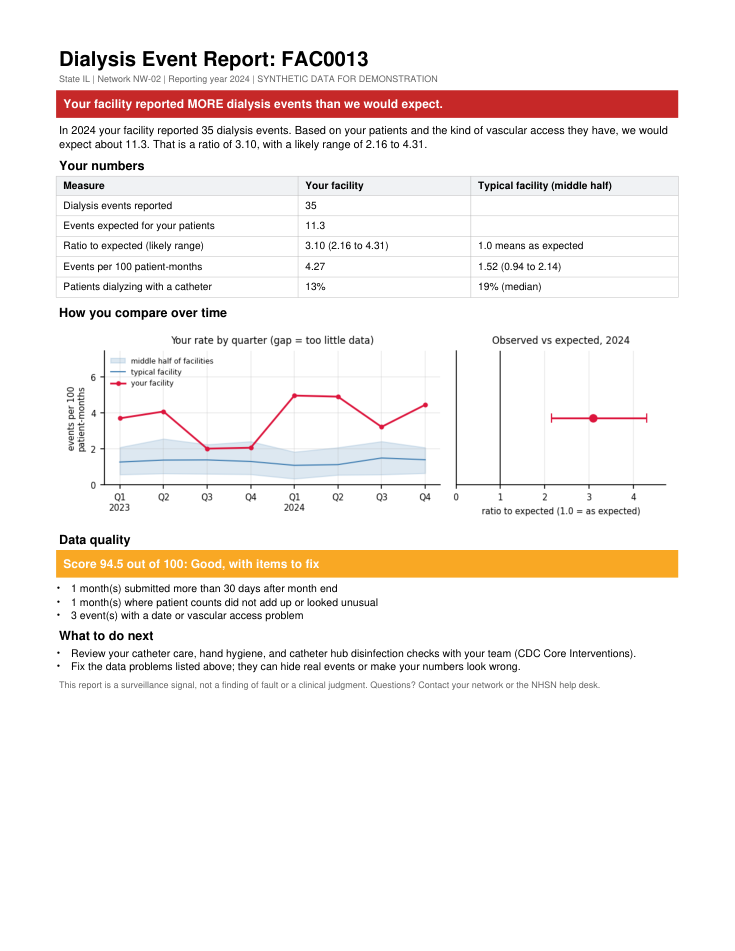

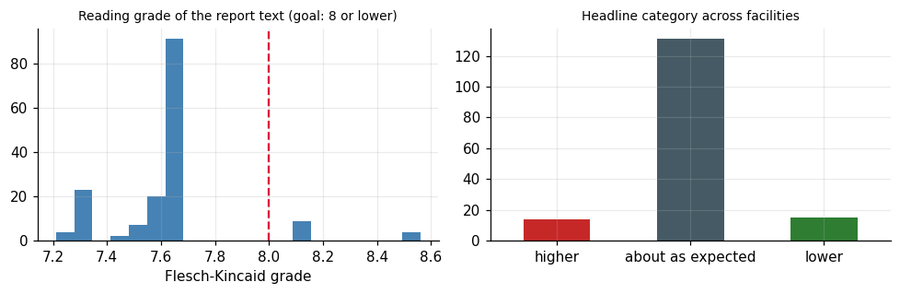

In [19]:
# One example of each situation, rendered from the actual PDF (a preview picture is also saved)
order = np.argsort(O_f / E_f); picks = {"higher": int(order[-1]), "typical": int(order[len(order) // 2]), "lower": int(order[0])}
poor = int(dq.score.to_numpy().argmin()); picks["poor data quality"] = poor
for k, i in picks.items():
    shutil.copy(f"{OUT}/reports_pdf/{fac_ids[i]}.pdf", f"{OUT}/samples/sample_{k.replace(' ', '_')}_{fac_ids[i]}.pdf"); shutil.copy(f"{OUT}/reports_html/{fac_ids[i]}.html", f"{OUT}/samples/sample_{k.replace(' ', '_')}_{fac_ids[i]}.html")
def render_preview(pdf_path, png_path, zoom=1.2):
    doc = pymupdf.open(pdf_path); pix = doc[0].get_pixmap(matrix=pymupdf.Matrix(zoom, zoom)); pix.save(png_path); doc.close()
show = picks["higher"]; render_preview(f"{OUT}/reports_pdf/{fac_ids[show]}.pdf", f"{OUT}/samples/preview_report_{fac_ids[show]}.png")
render_preview(f"{OUT}/reports_pdf/{fac_ids[poor]}.pdf", f"{OUT}/samples/preview_report_poor_dq_{fac_ids[poor]}.png")
print(f"Preview: {fac_ids[show]} (highest ratio)"); display(Image(filename=f"{OUT}/samples/preview_report_{fac_ids[show]}.png", width=640))

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(fk, bins=20, color="steelblue"); ax[0].axvline(8, color="crimson", ls="--"); ax[0].set_title("Reading grade of the report text (goal: 8 or lower)", fontsize=9); ax[0].set_xlabel("Flesch-Kincaid grade")
pd.Series(cats).value_counts().reindex(["higher", "about", "lower"]).plot.bar(ax=ax[1], color=["#c62828", "#455a64", "#2e7d32"]); ax[1].set_title("Headline category across facilities", fontsize=9); ax[1].set_xticklabels(["higher", "about as expected", "lower"], rotation=0)
plt.tight_layout(); plt.show()

# Part C. Training and web content
## 6. One-page handout: "How to read your rates"
A single page providers can keep at the nursing station. It uses a made-up worked example (not real data) and plain language, and the notebook checks that it fits on one page and measures its reading level.

Handout pages: 1 (target 1) | Flesch-Kincaid grade of the handout text: 5.7


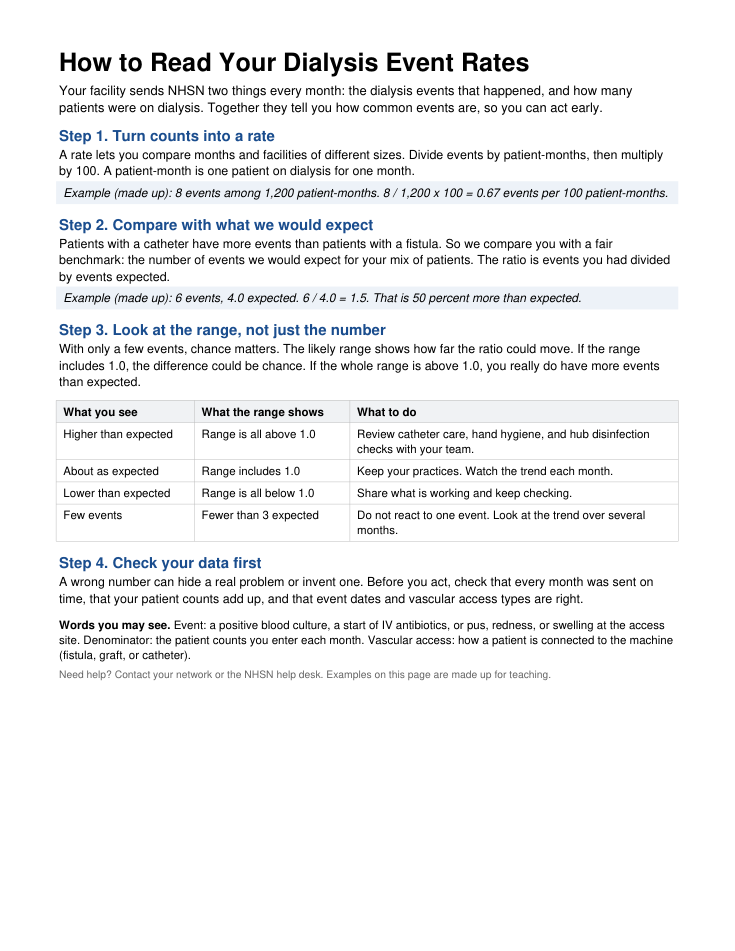

In [20]:
HANDOUT_TEXT = {
 "intro": "Your facility sends NHSN two things every month: the dialysis events that happened, and how many patients were on dialysis. Together they tell you how common events are, so you can act early.",
 "s1_head": "Step 1. Turn counts into a rate",
 "s1": "A rate lets you compare months and facilities of different sizes. Divide events by patient-months, then multiply by 100. A patient-month is one patient on dialysis for one month.",
 "s1_ex": "Example (made up): 8 events among 1,200 patient-months. 8 / 1,200 x 100 = 0.67 events per 100 patient-months.",
 "s2_head": "Step 2. Compare with what we would expect",
 "s2": "Patients with a catheter have more events than patients with a fistula. So we compare you with a fair benchmark: the number of events we would expect for your mix of patients. The ratio is events you had divided by events expected.",
 "s2_ex": "Example (made up): 6 events, 4.0 expected. 6 / 4.0 = 1.5. That is 50 percent more than expected.",
 "s3_head": "Step 3. Look at the range, not just the number",
 "s3": "With only a few events, chance matters. The likely range shows how far the ratio could move. If the range includes 1.0, the difference could be chance. If the whole range is above 1.0, you really do have more events than expected.",
 "s4_head": "Step 4. Check your data first",
 "s4": "A wrong number can hide a real problem or invent one. Before you act, check that every month was sent on time, that your patient counts add up, and that event dates and vascular access types are right.",
 "rows": [("Higher than expected", "Range is all above 1.0", "Review catheter care, hand hygiene, and hub disinfection checks with your team."),
          ("About as expected", "Range includes 1.0", "Keep your practices. Watch the trend each month."),
          ("Lower than expected", "Range is all below 1.0", "Share what is working and keep checking."),
          ("Few events", "Fewer than 3 expected", "Do not react to one event. Look at the trend over several months.")],
 "glossary": "Event: a positive blood culture, a start of IV antibiotics, or pus, redness, or swelling at the access site. Denominator: the patient counts you enter each month. Vascular access: how a patient is connected to the machine (fistula, graft, or catheter).",
 "foot": "Need help? Contact your network or the NHSN help desk. Examples on this page are made up for teaching."}

def build_handout(path):
    doc = SimpleDocTemplate(path, pagesize=letter, leftMargin=0.6 * inch, rightMargin=0.6 * inch, topMargin=0.45 * inch, bottomMargin=0.4 * inch, title="How to read your dialysis event rates")
    H = HANDOUT_TEXT
    def step(head, body, ex=None):
        out = [Paragraph(f"<b>{head}</b>", P(12.5, textColor=colors.HexColor("#1a4d8f"))), Spacer(1, 1), Paragraph(body, P(10.4))]
        if ex: out += [Spacer(1, 2), Table([[Paragraph(ex, P(10, font="Helvetica-Oblique"))]], colWidths=[7.2 * inch], style=[("BACKGROUND", (0, 0), (-1, -1), colors.HexColor("#eef3f8")), ("TOPPADDING", (0, 0), (-1, -1), 3), ("BOTTOMPADDING", (0, 0), (-1, -1), 3)])]
        return out + [Spacer(1, 9)]
    rows = [[Paragraph("<b>What you see</b>", P(9.6)), Paragraph("<b>What the range shows</b>", P(9.6)), Paragraph("<b>What to do</b>", P(9.6))]] + [[Paragraph(a, P(9.6)), Paragraph(b, P(9.6)), Paragraph(c, P(9.6))] for a, b, c in H["rows"]]
    tbl = Table(rows, colWidths=[1.6 * inch, 1.8 * inch, 3.8 * inch]); tbl.setStyle(TableStyle([("GRID", (0, 0), (-1, -1), 0.4, colors.HexColor("#bbbbbb")), ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#f1f3f4")), ("VALIGN", (0, 0), (-1, -1), "TOP")]))
    story = [Paragraph("How to Read Your Dialysis Event Rates", P(21, font="Helvetica-Bold")), Spacer(1, 3), Paragraph(H["intro"], P(10.8)), Spacer(1, 8)]
    story += step(H["s1_head"], H["s1"], H["s1_ex"]) + step(H["s2_head"], H["s2"], H["s2_ex"]) + step(H["s3_head"], H["s3"])
    story += [tbl, Spacer(1, 10)] + step(H["s4_head"], H["s4"]) + [Paragraph(f"<b>Words you may see.</b> {H['glossary']}", P(9.6)), Spacer(1, 5), Paragraph(H["foot"], P(8.6, textColor=colors.HexColor("#666666")))]
    doc.build(story)

build_handout(f"{OUT}/how_to_read_your_rates_handout.pdf")
hp = len(PdfReader(f"{OUT}/how_to_read_your_rates_handout.pdf").pages)
text_all = " ".join(str(v) if not isinstance(v, list) else " ".join(" ".join(x) for x in v) for v in HANDOUT_TEXT.values())
print(f"Handout pages: {hp} (target 1) | Flesch-Kincaid grade of the handout text: {fk_grade(text_all):.1f}")
render_preview(f"{OUT}/how_to_read_your_rates_handout.pdf", f"{OUT}/samples/preview_handout.png", zoom=1.2)
display(Image(filename=f"{OUT}/samples/preview_handout.png", width=640))

## 7. Draft web text: CVC reduction and bloodstream infection prevention
The draft below is written for dialysis staff and facility leaders. It is grounded in **CDC's Core Interventions for Dialysis Bloodstream Infection Prevention** (nine
interventions; see the references), in plain language, and ends with notes for the reviewers who must check it. **It is a draft for subject-matter review, not CDC-approved content.**
Specific figures and product guidance are deliberately left as marked placeholders for reviewers rather than recalled from memory.

In [21]:
WEBPAGE_MD = """# Preventing Bloodstream Infections in Dialysis: Using Your Data to Reduce Catheter Use

*DRAFT FOR REVIEW. Not approved content. See "Notes for reviewers" at the end.*

## Key points

- Bloodstream infections are a serious complication of dialysis. Good infection prevention in the dialysis facility protects patients.
- Catheters carry more infection risk than fistulas and grafts. Reducing catheter use is one of the most important steps a facility can take.
- CDC's Core Interventions are a set of nine practices shown to reduce bloodstream infections in dialysis facilities.
- Your NHSN data show where to focus. Check the data first, then use the rates to choose one thing to improve.

## Why catheters matter

A dialysis catheter is a tube that stays in a patient's body between treatments. Germs can travel along it and into the blood. A fistula or graft is built from the patient's own blood vessels or a graft, and it carries a lower risk of infection.

Some patients need a catheter for a time. The goal is to keep that time as short as possible, and to give every catheter the best possible care while it is in place.

## The nine Core Interventions

1. **Surveillance and feedback.** Report dialysis events to NHSN every month. Review your rates with staff and share what you learn.
2. **Hand hygiene.** Watch staff practice hand hygiene and give feedback.
3. **Vascular access care.** Watch how staff care for catheters, connect patients, and remove needles from fistulas and grafts. Give feedback.
4. **Staff education and competency.** Train all staff on infection control, including access care and aseptic technique. Check that each person can do it correctly.
5. **Patient education and engagement.** Give every patient the same standard education: how to protect the access, wash hands, know the risks of a catheter, spot signs of infection, and care for the access away from the unit.
6. **Catheter reduction.** Find and fix what stands in the way of a permanent access and of removing the catheter, such as patient education or a vascular access coordinator.
7. **Chlorhexidine for skin cleaning.** Use an alcohol-based chlorhexidine solution as the first choice to clean the skin when a catheter is placed and when the dressing is changed. [REVIEWER: confirm strength and wording against the current CDC page.]
8. **Catheter hub disinfection.** Scrub the catheter hub every time it is opened.
9. **Antimicrobial ointment at the catheter exit site.** Follow CDC guidance on choosing an ointment. [REVIEWER: link the current CDC guidance; do not name products here.]

## A simple plan to reduce catheter use

1. **Know where you stand.** Count the patients who use a catheter and track the share each month.
2. **Find the barriers.** For each catheter patient, ask what is in the way of a fistula or graft: referral, surgery scheduling, patient worries, or health.
3. **Work with the care team.** Talk with the kidney doctor and the access surgeon early. Name one person to coordinate access plans.
4. **Talk with patients.** Explain the risks of a catheter and the options in simple words. Ask what worries them.
5. **Check progress.** Review the catheter share and your event rates each quarter. Share good news with the team.

## Using your NHSN data

- **Check your data first.** Make sure every month was sent on time, patient counts add up, and dates and access types are right.
- **Read the ratio.** Compare the events you had with the events expected for your patients. A ratio above 1.0 means more than expected. Look at the likely range: if it includes 1.0, the difference could be chance.
- **Look at the trend.** One quarter can be unusual. Look at several quarters.
- **Pick one action.** Choose one Core Intervention to strengthen, then check your numbers again next quarter.

Our one-page handout, *How to Read Your Dialysis Event Rates*, walks through these steps with an example.

## Resources

- CDC Dialysis Safety: https://www.cdc.gov/dialysis-safety/hcp/clinical-safety
- Core Interventions checklists and audit tools: [REVIEWER: add current links]
- NHSN Dialysis Event Module and protocol: [REVIEWER: add current links]

## Notes for reviewers

- This text is a portfolio draft. It has not been reviewed by subject-matter experts and must not be published as is.
- Check every clinical statement, product reference, number, and link against current CDC guidance.
- Items marked [REVIEWER] are intentionally left open.
- No data on this page come from real facilities.
"""
open(f"{OUT}/dialysis_safety_webpage_draft.md", "w").write(WEBPAGE_MD)
body = re.sub(r"\[REVIEWER[^\]]*\]", "", WEBPAGE_MD.split("## Notes for reviewers")[0]); body = re.sub(r"[#*_`]|https?://\S+", "", body)
print(f"Web text: {len(re.findall(r'[A-Za-z]+', body)):,} words | Flesch-Kincaid grade {fk_grade(body):.1f} | sections: {WEBPAGE_MD.count(chr(10) + '## ')}")

Web text: 621 words | Flesch-Kincaid grade 6.1 | sections: 7


In [22]:
inq.drop(columns=["period"]).to_csv(f"{OUT}/synthetic_inquiries.csv", index=False)
pd.DataFrame({"month": te.month, "topic": te.topic, "text": te.text, **{f"pred_{n}": [TOPICS[i] for i in p.argmax(1)] for n, p in probs.items()}, "confidence_tfidf": conf_te}).to_csv(f"{OUT}/inquiry_test_predictions.csv", index=False)
plan.to_csv(f"{OUT}/staffing_forecast.csv", index=False)
fac_out = pd.DataFrame([facility_fields(i) for i in range(F)]).drop(columns=["dq_problems"]); fac_out["reading_grade"] = fk; fac_out.to_csv(f"{OUT}/facility_report_summary.csv", index=False)
with pd.ExcelWriter(f"{OUT}/communication_automation_report.xlsx", engine="openpyxl") as xw:
    res.to_excel(xw, sheet_name="Triage accuracy", index=False); rep.reset_index(names="topic").to_excel(xw, sheet_name="Per-topic", index=False)
    tau_tbl.to_excel(xw, sheet_name="Auto-route thresholds", index=False); fc_tbl.to_excel(xw, sheet_name="Forecast comparison", index=False); plan.to_excel(xw, sheet_name="Staffing plan", index=False)
    fac_out.to_excel(xw, sheet_name="Facility report summary", index=False); dq.reset_index(names="facility_id").to_excel(xw, sheet_name="Data quality 2024", index=False)
    for ws in xw.book.worksheets:
        for column in ws.columns: ws.column_dimensions[column[0].column_letter].width = min(50, max(11, max(len(str(c.value or "")) for c in column[:40]) + 2))
        ws.freeze_panes = "A2"
shutil.make_archive(f"{OUT}/facility_reports_pdf", "zip", f"{OUT}/reports_pdf"); shutil.make_archive(f"{OUT}/facility_reports_html", "zip", f"{OUT}/reports_html")
print(sorted(f for f in os.listdir(OUT) if not os.path.isdir(f"{OUT}/{f}")))

['communication_automation_report.xlsx', 'dialysis_safety_webpage_draft.md',
    'facility_report_summary.csv', 'facility_reports_html.zip', 'facility_reports_pdf.zip',
    'how_to_read_your_rates_handout.pdf', 'inquiry_test_predictions.csv', 'staffing_forecast.csv',
    'synthetic_inquiries.csv']


## 8. So what for public health?
- **Test triage on how people actually write, not on how the training set was written.** The gap between familiar and novel phrasing is the number to watch before trusting any classifier,
  and an auto-route threshold chosen in advance turns an imperfect model into a safe workflow (confident cases routed, doubtful ones to a person).
- **Forecast with intervals and test the intervals.** A staffing plan needs a range and the probability of a surge, and it should be built from a model whose interval coverage was checked by rolling forward in time.
- **Automate the report, keep the human in the loop.** One generator produced 160 consistent one-page reports in seconds, with the logic written in advance and reviewable by staff. The same code makes the
  reading level and page count testable, which a manual process rarely is.
- **Say what the numbers do not mean.** Each report states that the ratio is a surveillance signal, shows the likely range, and warns when few events make a ratio unstable.
- **Draft content needs reviewers and placeholders, not confident guesses.** Specific numbers and product guidance are left for subject-matter experts to fill in from current CDC sources.

## Limitations
- Inquiry texts are template-generated. Real messages are messier, longer, and often about several things. Treat all accuracy figures as illustrative.
- If the pretrained embedding model could not be downloaded, the transformer comparison used only a small model trained from scratch and the conclusions about pretrained models are untested. Check the backend line.
- Monthly volume is simulated to match the posting's figures (212, range 122 to 415). The seasonal pattern, surge, and the 250-per-FTE capacity are assumptions.
- Only 36 months of volume exist, so seasonal models see two or three cycles at most. Forecast intervals are wide for a reason.
- Facility reports use the simplified data-quality score and a pooled benchmark from the same synthetic year. The wording has not been tested with real users.
- The readability formula is a rough proxy. Usability testing with dialysis staff is the real check.
- The web text is an unreviewed draft grounded in CDC's published Core Interventions. It is not CDC content.

## Delivered alongside this notebook
A **7-slide training deck** for dialysis providers (delivered as a slide deck, downloadable as PowerPoint or PDF), and the README for this project.

## References
- CDC. Core Interventions for Dialysis Bloodstream Infection (BSI) Prevention. https://www.cdc.gov/dialysis-safety/hcp/clinical-safety
- Hyndman RJ, Athanasopoulos G. *Forecasting: Principles and Practice*, 3rd ed. OTexts, 2021.
- Kincaid JP, Fishburne RP, Rogers RL, Chissom BS. Derivation of new readability formulas for Navy enlisted personnel. 1975.
- Reimers N, Gurevych I. Sentence-BERT: sentence embeddings using Siamese BERT-networks. EMNLP 2019.